# 🔬 APT Data Augmentation Pipeline
## CTGAN, TVAE & CVAE - Comprehensive Synthetic Data Generation

---

### 📌 Project Overview
This notebook implements **three state-of-the-art generative models** for creating high-quality synthetic APT (Advanced Persistent Threat) malicious data:

1. **CTGAN** - Conditional Tabular GAN with mode-specific normalization
2. **TVAE** - Tabular Variational Autoencoder for stable training
3. **CVAE** - Conditional VAE for condition-guided generation

All models use **predefined feature-selected columns** with ≥50% data completeness for optimal generation quality.

### 🔄 Pipeline Architecture

```
┌─────────────────┐    ┌─────────────────┐    ┌─────────────────┐
│  1. Data Load   │───▶│  2. Create      │───▶│  3. Preprocess  │
│  & Analysis     │    │  Boolean Flags  │    │  Data           │
└─────────────────┘    └─────────────────┘    └─────────────────┘
                                                      │
                              ┌────────────────────────┴────────────────────────┐
                              ▼                        ▼                        ▼
                     ┌─────────────┐          ┌─────────────┐          ┌─────────────┐
                     │    CTGAN    │          │    TVAE     │          │    CVAE     │
                     │   Training  │          │   Training  │          │   Training  │
                     └──────┬──────┘          └──────┬──────┘          └──────┬──────┘
                            │                        │                        │
                            └────────────────────────┼────────────────────────┘
                                                     ▼
                                          ┌─────────────────────┐
                                          │  Compare & Evaluate │
                                          │   Select Best Model │
                                          └─────────────────────┘
```

### 🎯 Model Comparison

| Model | Architecture | Best For | Training Stability | Speed |
|-------|-------------|----------|-------------------|-------|
| **CTGAN** | GAN (adversarial) | Mixed categorical/numeric | Moderate | Slow |
| **TVAE** | VAE (reconstruction) | High-cardinality categorical | High | Fast |
| **CVAE** | Conditional VAE | Condition-guided generation | High | Fast |

### 📊 Expected Input
- **Source**: Wazuh SIEM malicious APT alerts
- **Format**: Excel files (malicious_ctgan.xlsx, malicious_tvae.xlsx)
- **Samples**: ~25,000 malicious events

### 📁 Outputs Generated
- Synthetic data from CTGAN, TVAE, and CVAE
- Combined real+synthetic datasets
- Comprehensive quality comparison report
- Trained model checkpoints

In [9]:
# ============================================================================
# 📦 PART 1: INSTALL REQUIRED PACKAGES
# ============================================================================
# Run this cell first to ensure all dependencies are available
# ============================================================================

!pip install ctgan sdv transformers sentence-transformers openpyxl -q

print("=" * 70)
print("✅ PACKAGE INSTALLATION COMPLETE")
print("=" * 70)
print("""
📦 Installed Packages:
   • ctgan         - Conditional Tabular GAN for synthetic data
   • sdv           - Synthetic Data Vault (CTGAN dependency)
   • transformers  - HuggingFace library for SecBERT
   • sentence-transformers - Fallback SBERT embeddings
   • openpyxl      - Excel file reading
""")

✅ PACKAGE INSTALLATION COMPLETE

📦 Installed Packages:
   • ctgan         - Conditional Tabular GAN for synthetic data
   • sdv           - Synthetic Data Vault (CTGAN dependency)
   • transformers  - HuggingFace library for SecBERT
   • sentence-transformers - Fallback SBERT embeddings
   • openpyxl      - Excel file reading



In [11]:
# ============================================================================
# 📚 PART 2: IMPORTS & ENVIRONMENT SETUP
# ============================================================================

# Suppress CUDA/TensorFlow warnings (MUST be before any imports)
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GLOG_minloglevel'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import warnings
import ast
import re
import json
from datetime import datetime

# Suppress warnings
warnings.filterwarnings('ignore')
import logging
logging.getLogger('absl').setLevel(logging.ERROR)

# Set plotting style for professional visualizations
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# PyTorch - GPU acceleration
import torch

# Sklearn - Preprocessing and feature selection
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

#ctgan
from ctgan import CTGAN

---
## ⚙️ Part 3: Configuration

All hyperparameters centralized for easy tuning and reproducibility.

### 🔧 Key Parameters to Tune

| Parameter | Default | Description | Impact |
|-----------|---------|-------------|--------|
| `missing_threshold` | 0.80 | Drop columns with >80% missing | Lower = stricter filtering |
| `tfidf_features` | 50 | TF-IDF vocabulary size | Higher = more log detail |
| `secbert_dim` | 64 | SecBERT PCA dimensions | Higher = more semantic info |
| `n_features_to_select` | 30 | Final features for CTGAN | Lower = better quality |
| `ctgan_epochs` | 500 | Training iterations | Higher = better but slower |

In [12]:
# ============================================================================
# CONFIGURATION
# ============================================================================
# Centralized settings for the entire pipeline
# ============================================================================

CONFIG = {
    # ==========================================================================
    # DATA PATHS
    # ==========================================================================
    'ctgan_data_path': 'malicious_ctgan.xlsx',  # CTGAN data file
    'tvae_data_path': 'malicious_tvae.xlsx',    # TVAE data file
    'output_dir': 'ctgan_output',

    # ==========================================================================
    # LABEL & CONDITION COLUMNS
    # ==========================================================================
    'label_col': 'malicious',
    'condition_col': 'cyber_kill_chain_tactic',

    # ==========================================================================
    # CTGAN HYPERPARAMETERS
    # ==========================================================================
    'ctgan_epochs': 500,
    'ctgan_batch_size': 500,
    'generator_dim': (256, 256),
    'discriminator_dim': (256, 256),
    'pac': 10,

    # ==========================================================================
    # TVAE HYPERPARAMETERS
    # ==========================================================================
    'tvae_epochs': 500,
    'tvae_batch_size': 500,
    'tvae_compress_dims': (128, 128),
    'tvae_decompress_dims': (128, 128),

    # ==========================================================================
    # CVAE HYPERPARAMETERS
    # ==========================================================================
    'cvae_epochs': 500,
    'cvae_batch_size': 256,
    'cvae_latent_dim': 32,
    'cvae_hidden_dims': [256, 128],
    'cvae_learning_rate': 1e-3,
    'cvae_beta': 1.0,  # KL divergence weight

    # ==========================================================================
    # GENERATION SETTINGS
    # ==========================================================================
    'synthetic_ratio': 2.0,

    # ==========================================================================
    # QUALITY THRESHOLDS
    # ==========================================================================
    'ks_threshold': 0.3,
    'l1_threshold': 0.3,
}

# ============================================================================
# 📋 PREDEFINED COLUMNS FOR ALL MODELS
# ============================================================================
# Only columns with ≥50% data completeness are included
# Sparse columns (audit, syscheck, SCA) are excluded for better quality
# Boolean flags will be CREATED during preprocessing from existing data

CTGAN_COLUMNS = [
    # Target
    'malicious',

    # Cyber Kill Chain features (>96% complete)
    'cyber_kill_chain_tactic',
    'cyber_kill_chain_technique',

    # MITRE ATT&CK features (>97% complete)
    '_source.rule.mitre.id',
    '_source.rule.mitre.tactic',

    # Rule features (100% complete)
    '_source.rule.level',
    '_source.rule.groups',
    '_source.decoder.name',

    # Network features (>73% complete)
    '_source.data.protocol',
]

# TVAE/CVAE can handle additional boolean flags
TVAE_COLUMNS = CTGAN_COLUMNS + [
    'has_audit',
    'has_syscheck',
    'has_sca',
    '_source.data.audit.syscall',
    '_source.syscheck.event',
]

# CVAE uses same columns as TVAE (handles conditions well)
CVAE_COLUMNS = TVAE_COLUMNS.copy()

# Columns to use for creating boolean flags (these won't be in final training data)
AUDIT_INDICATOR_COLS = ['_source.data.audit.syscall', '_source.data.audit.uid', '_source.data.audit.euid', '_source.data.audit.gid', '_source.data.audit.auid', '_source.data.audit.success', '_source.data.audit.exit']
SYSCHECK_INDICATOR_COLS = ['_source.syscheck.event', '_source.syscheck.perm_before', '_source.syscheck.perm_after', '_source.syscheck.size_before', '_source.syscheck.size_after']
SCA_INDICATOR_COLS = ['_source.data.sca.check.compliance.mitre_tactics', '_source.data.sca.check.compliance.mitre_techniques']

# Create output directory
Path(CONFIG['output_dir']).mkdir(exist_ok=True)

print("✅ Configuration loaded!")
print(f"\n📋 Key Settings:")
print(f"   • CTGAN columns: {len(CTGAN_COLUMNS)}")
print(f"   • TVAE columns: {len(TVAE_COLUMNS)}")
print(f"   • CVAE columns: {len(CVAE_COLUMNS)}")
print(f"   • CTGAN epochs: {CONFIG['ctgan_epochs']}")
print(f"   • TVAE epochs: {CONFIG['tvae_epochs']}")
print(f"   • CVAE epochs: {CONFIG['cvae_epochs']}")
print(f"   • Synthetic ratio: {CONFIG['synthetic_ratio']}x")

✅ Configuration loaded!

📋 Key Settings:
   • CTGAN columns: 9
   • TVAE columns: 12
   • CVAE columns: 12
   • CTGAN epochs: 500
   • TVAE epochs: 500
   • CVAE epochs: 500
   • Synthetic ratio: 2.0x


---
## 📂 Part 4: Load & Explore Data

Load the Wazuh SIEM malicious APT data and perform initial exploratory data analysis.

In [13]:
# ============================================================================
# 📂 LOAD DATA - SEPARATE FILES FOR CTGAN AND TVAE
# ============================================================================

print("=" * 70)
print("📂 LOADING DATA (SEPARATE FILES)")
print("=" * 70)

# Helper function to create boolean flags
def check_any_not_null(df, cols):
    """Check if any of the columns has non-null values for each row"""
    existing_cols = [c for c in cols if c in df.columns]
    if not existing_cols:
        return pd.Series([False] * len(df), index=df.index)
    return df[existing_cols].notna().any(axis=1)

# ============================================================================
# LOAD CTGAN DATA
# ============================================================================
print("🔹 Loading CTGAN data...")
ctgan_paths = [
    CONFIG.get("ctgan_data_path", "malicious_ctgan.xlsx"),
    "malicious_ctgan.xlsx",
    "/kaggle/input/apt-data/malicious_ctgan.xlsx",
    "../data/malicious_ctgan.xlsx",
    "/home/yacine/Desktop/PFE/Model/ML_models/months-data/malicious_ctgan.xlsx",
]

ctgan_raw_data = None
for path in ctgan_paths:
    if Path(path).exists():
        print(f"   📁 Found CTGAN data at: {path}")
        if path.endswith(".xlsx"):
            ctgan_raw_data = pd.read_excel(path, sheet_name="Sheet1")
        else:
            ctgan_raw_data = pd.read_csv(path, low_memory=False)
        CONFIG["ctgan_data_path"] = path
        break

if ctgan_raw_data is None:
    raise FileNotFoundError(f"Could not find CTGAN data file. Tried: {ctgan_paths}")

# Create boolean flags from sparse indicator columns
print("🔧 Creating boolean flags for CTGAN data...")
ctgan_raw_data['has_audit'] = check_any_not_null(ctgan_raw_data, AUDIT_INDICATOR_COLS)
ctgan_raw_data['has_syscheck'] = check_any_not_null(ctgan_raw_data, SYSCHECK_INDICATOR_COLS)
ctgan_raw_data['has_sca'] = check_any_not_null(ctgan_raw_data, SCA_INDICATOR_COLS)

# Filter CTGAN columns from the loaded data
ctgan_existing = [col for col in CTGAN_COLUMNS if col in ctgan_raw_data.columns]
ctgan_missing = [col for col in CTGAN_COLUMNS if col not in ctgan_raw_data.columns]

print(f"   ✅ CTGAN data loaded: {ctgan_raw_data.shape[0]:,} rows × {ctgan_raw_data.shape[1]} columns")
print(f"   📋 CTGAN columns: {len(ctgan_existing)}/{len(CTGAN_COLUMNS)} found")
if ctgan_missing:
    print(f"   ⚠️ Missing CTGAN columns: {ctgan_missing}")

# Create CTGAN dataframe
df_ctgan = ctgan_raw_data[ctgan_existing].copy()

# ============================================================================
# LOAD TVAE DATA
# ============================================================================
print("\n🔹 Loading TVAE data...")
tvae_paths = [
    CONFIG.get("tvae_data_path", "malicious_tvae.xlsx"),
    "malicious_tvae.xlsx",
    "/kaggle/input/apt-data/malicious_tvae.xlsx",
    "../data/malicious_tvae.xlsx",
    "/home/yacine/Desktop/PFE/Model/ML_models/months-data/malicious_tvae.xlsx",
]

tvae_raw_data = None
for path in tvae_paths:
    if Path(path).exists():
        print(f"   📁 Found TVAE data at: {path}")
        if path.endswith(".xlsx"):
            tvae_raw_data = pd.read_excel(path, sheet_name="Sheet1")
        else:
            tvae_raw_data = pd.read_csv(path, low_memory=False)
        CONFIG["tvae_data_path"] = path
        break

if tvae_raw_data is None:
    raise FileNotFoundError(f"Could not find TVAE data file. Tried: {tvae_paths}")

# Create boolean flags from sparse indicator columns
print("🔧 Creating boolean flags for TVAE data...")
tvae_raw_data['has_audit'] = check_any_not_null(tvae_raw_data, AUDIT_INDICATOR_COLS)
tvae_raw_data['has_syscheck'] = check_any_not_null(tvae_raw_data, SYSCHECK_INDICATOR_COLS)
tvae_raw_data['has_sca'] = check_any_not_null(tvae_raw_data, SCA_INDICATOR_COLS)

# Filter TVAE columns from the loaded data
tvae_existing = [col for col in TVAE_COLUMNS if col in tvae_raw_data.columns]
tvae_missing = [col for col in TVAE_COLUMNS if col not in tvae_raw_data.columns]

print(f"   ✅ TVAE data loaded: {tvae_raw_data.shape[0]:,} rows × {tvae_raw_data.shape[1]} columns")
print(f"   📋 TVAE columns: {len(tvae_existing)}/{len(TVAE_COLUMNS)} found")
if tvae_missing:
    print(f"   ⚠️ Missing TVAE columns: {tvae_missing}")

# Create TVAE dataframe
df_tvae = tvae_raw_data[tvae_existing].copy()

# ============================================================================
# SUMMARY
# ============================================================================
print(f"""
✅ DATA LOADED SUCCESSFULLY!

📊 Dataset Overview:
   ┌─────────────────────────────────────────────────────────────┐
   │  CTGAN Data:                                                │
   │     Rows: {len(df_ctgan):>8,}                                    │
   │     Columns: {len(df_ctgan.columns):>3} ({len(ctgan_existing)}/{len(CTGAN_COLUMNS)} requested)           │
   │     Memory: {df_ctgan.memory_usage(deep=True).sum() / 1e6:>7.2f} MB                        │
   ├─────────────────────────────────────────────────────────────┤
   │  TVAE Data:                                                 │
   │     Rows: {len(df_tvae):>8,}                                    │
   │     Columns: {len(df_tvae.columns):>3} ({len(tvae_existing)}/{len(TVAE_COLUMNS)} requested)           │
   │     Memory: {df_tvae.memory_usage(deep=True).sum() / 1e6:>7.2f} MB                        │
   └─────────────────────────────────────────────────────────────┘
""")

print("=" * 70)

📂 LOADING DATA (SEPARATE FILES)
🔹 Loading CTGAN data...
   📁 Found CTGAN data at: malicious_ctgan.xlsx
🔧 Creating boolean flags for CTGAN data...
   ✅ CTGAN data loaded: 25,418 rows × 28 columns
   📋 CTGAN columns: 9/9 found

🔹 Loading TVAE data...
   📁 Found TVAE data at: malicious_tvae.xlsx
🔧 Creating boolean flags for TVAE data...
   ✅ TVAE data loaded: 25,418 rows × 37 columns
   📋 TVAE columns: 12/12 found

✅ DATA LOADED SUCCESSFULLY!

📊 Dataset Overview:
   ┌─────────────────────────────────────────────────────────────┐
   │  CTGAN Data:                                                │
   │     Rows:   25,418                                    │
   │     Columns:   9 (9/9 requested)           │
   │     Memory:   11.45 MB                        │
   ├─────────────────────────────────────────────────────────────┤
   │  TVAE Data:                                                 │
   │     Rows:   25,418                                    │
   │     Columns:  12 (12/12 requested)   

📊 EXPLORATORY DATA ANALYSIS - SELECTED FEATURES

📌 Data Types Distribution (CTGAN columns):
   • object             7 columns ( 77.8%)
   • int64              2 columns ( 22.2%)

📌 Missing Values Summary:
   • Complete columns (0% missing): 4
   • Partial columns (0-80% missing): 5
   • Mostly missing (>80%): 0



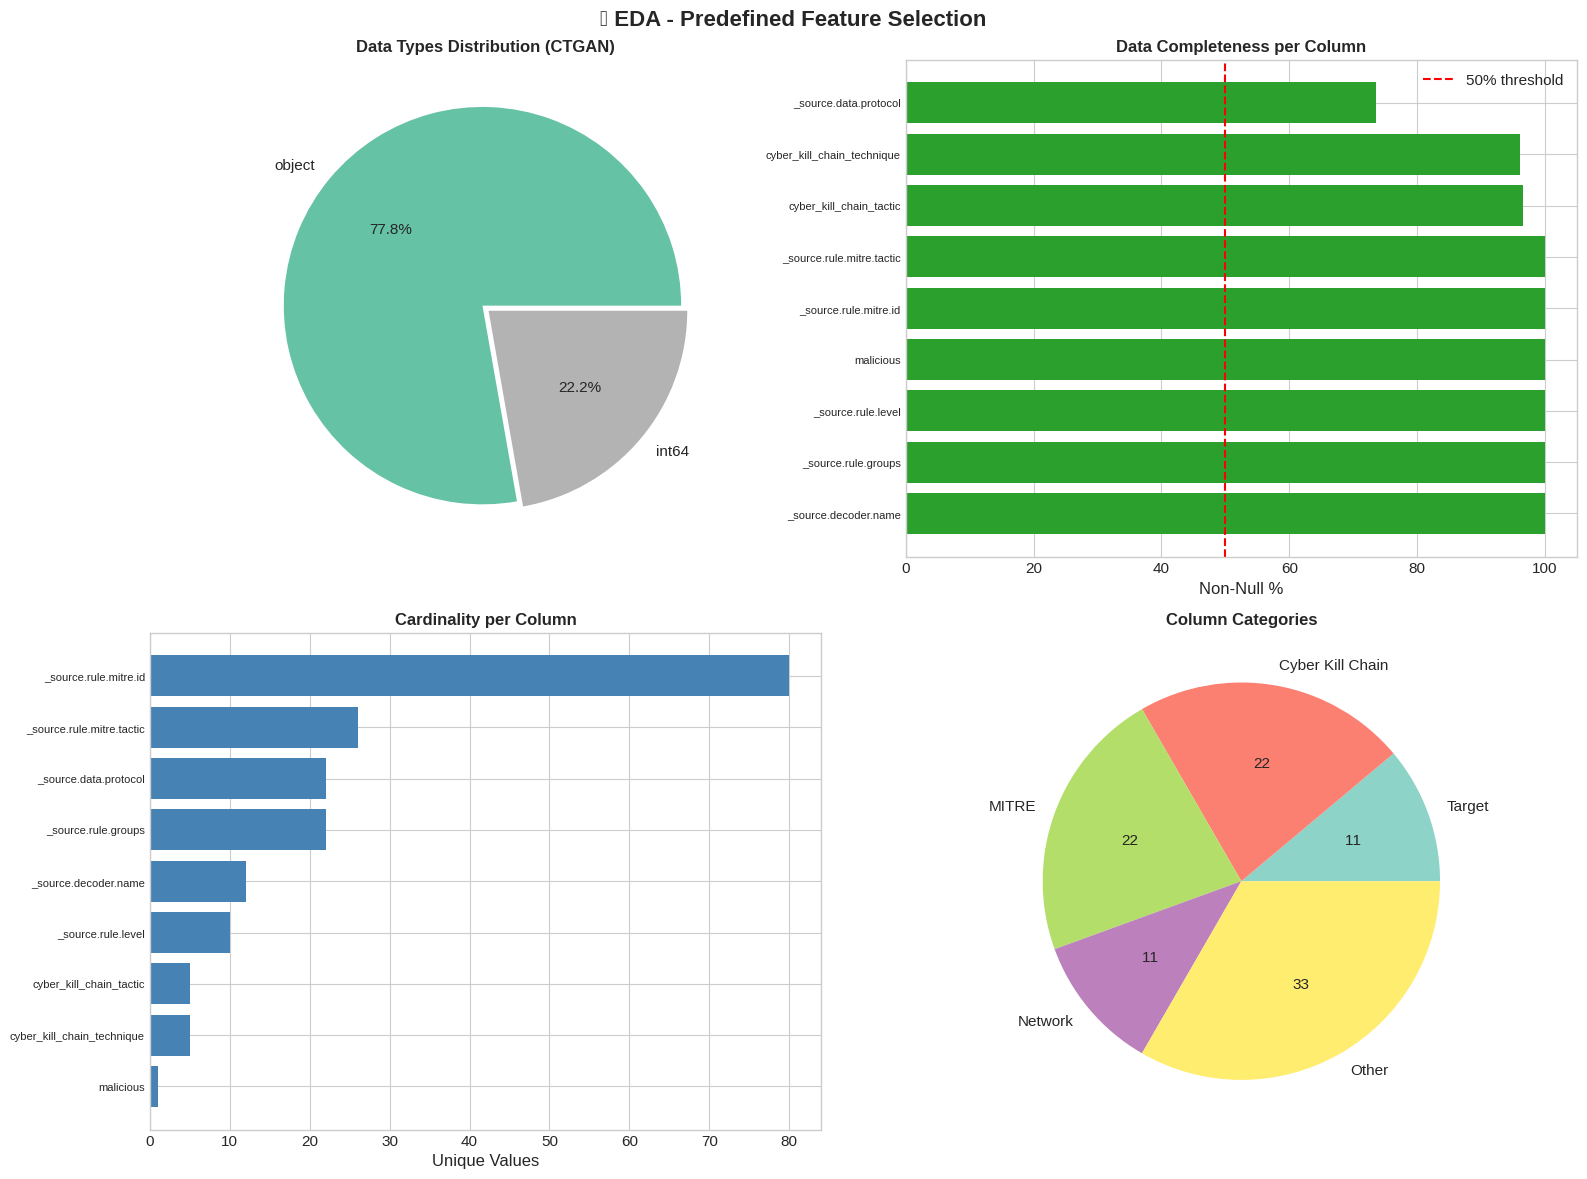


✅ EDA visualization saved to ctgan_output/eda_overview.png


In [14]:
# ============================================================================
# 📊 EXPLORATORY DATA ANALYSIS (EDA) - PREDEFINED COLUMNS
# ============================================================================

print("=" * 70)
print("📊 EXPLORATORY DATA ANALYSIS - SELECTED FEATURES")
print("=" * 70)

# Use CTGAN dataframe for EDA (it's the more restrictive one)
df = df_ctgan.copy()

# ========== 1. DATA TYPES BREAKDOWN ==========
dtype_counts = df.dtypes.value_counts()
print(f"\n📌 Data Types Distribution (CTGAN columns):")
for dtype, count in dtype_counts.items():
    pct = count / len(df.columns) * 100
    print(f"   • {str(dtype):<15} {count:>4} columns ({pct:>5.1f}%)")

# ========== 2. MISSING VALUES ANALYSIS ==========
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
n_complete = (missing_pct == 0).sum()
n_partial = ((missing_pct > 0) & (missing_pct < 80)).sum()
n_mostly_missing = (missing_pct >= 80).sum()

print(f"""
📌 Missing Values Summary:
   • Complete columns (0% missing): {n_complete}
   • Partial columns (0-80% missing): {n_partial}
   • Mostly missing (>80%): {n_mostly_missing}
""")

# ========== 3. VISUALIZATIONS ==========
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('📊 EDA - Predefined Feature Selection', fontsize=16, fontweight='bold')

# Plot 1: Data Types Distribution
ax1 = axes[0, 0]
colors = plt.cm.Set2(np.linspace(0, 1, len(dtype_counts)))
wedges, texts, autotexts = ax1.pie(
    dtype_counts.values,
    labels=[str(d) for d in dtype_counts.index],
    autopct='%1.1f%%',
    colors=colors,
    explode=[0.02] * len(dtype_counts)
)
ax1.set_title('Data Types Distribution (CTGAN)', fontsize=12, fontweight='bold')

# Plot 2: Missing Values per Column
ax2 = axes[0, 1]
non_null_pct = 100 - missing_pct
colors_missing = ['#2ca02c' if x >= 50 else '#ff7f0e' if x >= 20 else '#d62728' for x in non_null_pct.values]
bars = ax2.barh(range(len(non_null_pct)), non_null_pct.values, color=colors_missing)
ax2.set_yticks(range(len(non_null_pct)))
ax2.set_yticklabels([c[:35] for c in non_null_pct.index], fontsize=8)
ax2.set_xlabel('Non-Null %')
ax2.axvline(x=50, color='red', linestyle='--', label='50% threshold')
ax2.legend()
ax2.set_title('Data Completeness per Column', fontsize=12, fontweight='bold')
ax2.invert_yaxis()

# Plot 3: Cardinality Analysis
ax3 = axes[1, 0]
cardinality = df.nunique().sort_values(ascending=False)
ax3.barh(range(len(cardinality)), cardinality.values, color='steelblue')
ax3.set_yticks(range(len(cardinality)))
ax3.set_yticklabels([c[:35] for c in cardinality.index], fontsize=8)
ax3.set_xlabel('Unique Values')
ax3.set_title('Cardinality per Column', fontsize=12, fontweight='bold')
ax3.invert_yaxis()

# Plot 4: Column Category Distribution
ax4 = axes[1, 1]
column_categories = {
    'Target': len([c for c in df.columns if c == 'malicious']),
    'Cyber Kill Chain': len([c for c in df.columns if 'cyber_kill_chain' in c]),
    'MITRE': len([c for c in df.columns if 'mitre' in c.lower()]),
    'Audit': len([c for c in df.columns if 'audit' in c]),
    'Syscheck': len([c for c in df.columns if 'syscheck' in c]),
    'SCA': len([c for c in df.columns if 'sca' in c]),
    'Network': len([c for c in df.columns if any(x in c for x in ['protocol', 'srcport'])]),
    'Other': len([c for c in df.columns if not any(x in c for x in ['malicious', 'cyber_kill_chain', 'mitre', 'audit', 'syscheck', 'sca', 'protocol', 'srcport'])]),
}
column_categories = {k: v for k, v in column_categories.items() if v > 0}
ax4.pie(column_categories.values(), labels=column_categories.keys(), autopct='%1.0f',
        colors=plt.cm.Set3(np.linspace(0, 1, len(column_categories))))
ax4.set_title('Column Categories', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(Path(CONFIG['output_dir']) / 'eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ EDA visualization saved to {CONFIG['output_dir']}/eda_overview.png")

---
## 🔧 Part 5: Data Preprocessing

Since we're using **predefined feature-selected columns**, we skip automatic column filtering and directly preprocess the data for CTGAN and TVAE.

### 📋 Preprocessing Steps
1. Handle missing values (fill with 'MISSING' for categorical, median for numeric)
2. Convert categorical columns to strings
3. Identify discrete columns for CTGAN/TVAE
4. Prepare separate dataframes for each model

In [15]:
# ============================================================================
# 🔧 DATA PREPROCESSING FOR CTGAN AND TVAE
# ============================================================================

print("=" * 70)
print("🔧 DATA PREPROCESSING")
print("=" * 70)

def preprocess_for_gan(df, model_name='CTGAN'):
    """
    Preprocess data for CTGAN/TVAE
    - Handle missing values
    - Convert categorical to strings
    - Identify discrete columns
    """
    df_processed = df.copy()
    discrete_columns = []

    for col in df_processed.columns:
        # Analyze column
        n_unique = df_processed[col].nunique()
        dtype = df_processed[col].dtype

        if dtype == 'object' or dtype.name == 'category':
            # Categorical column
            df_processed[col] = df_processed[col].fillna('MISSING').astype(str)
            discrete_columns.append(col)

        elif dtype in ['int64', 'float64']:
            # Check if it's really categorical (low cardinality)
            if n_unique <= 20:
                df_processed[col] = df_processed[col].fillna(-1).astype(str)
                discrete_columns.append(col)
            else:
                # Numeric - fill with median
                df_processed[col] = df_processed[col].fillna(df_processed[col].median())

        elif dtype == 'bool':
            df_processed[col] = df_processed[col].fillna(False).astype(str)
            discrete_columns.append(col)

        else:
            # Default to categorical
            df_processed[col] = df_processed[col].fillna('MISSING').astype(str)
            discrete_columns.append(col)

    print(f"\n📋 {model_name} Preprocessing Results:")
    print(f"   • Total columns: {len(df_processed.columns)}")
    print(f"   • Discrete columns: {len(discrete_columns)}")
    print(f"   • Continuous columns: {len(df_processed.columns) - len(discrete_columns)}")

    return df_processed, discrete_columns

# Preprocess CTGAN data
df_ctgan_processed, ctgan_discrete_cols = preprocess_for_gan(df_ctgan, 'CTGAN')

# Preprocess TVAE data
df_tvae_processed, tvae_discrete_cols = preprocess_for_gan(df_tvae, 'TVAE')

# ========== SUMMARY ==========
print(f"\n" + "=" * 70)
print("📊 PREPROCESSING SUMMARY")
print("=" * 70)

print(f"""
🔹 CTGAN Dataset:
   • Shape: {df_ctgan_processed.shape}
   • Discrete columns: {len(ctgan_discrete_cols)}
   • Columns: {list(df_ctgan_processed.columns)}

🔹 TVAE Dataset:
   • Shape: {df_tvae_processed.shape}
   • Discrete columns: {len(tvae_discrete_cols)}
   • Additional columns vs CTGAN: {set(df_tvae_processed.columns) - set(df_ctgan_processed.columns)}
""")

# Show column details
print("\n📋 CTGAN COLUMNS DETAIL:")
print("-" * 70)
for col in df_ctgan_processed.columns:
    is_discrete = "📊 Discrete" if col in ctgan_discrete_cols else "📈 Continuous"
    n_unique = df_ctgan_processed[col].nunique()
    non_null = (df_ctgan[col].notna().sum() / len(df_ctgan) * 100)
    print(f"   {is_discrete} | {col[:40]:<40} | {n_unique:>5} unique | {non_null:>5.1f}% non-null")

print("\n" + "=" * 70)

🔧 DATA PREPROCESSING

📋 CTGAN Preprocessing Results:
   • Total columns: 9
   • Discrete columns: 9
   • Continuous columns: 0

📋 TVAE Preprocessing Results:
   • Total columns: 12
   • Discrete columns: 12
   • Continuous columns: 0

📊 PREPROCESSING SUMMARY

🔹 CTGAN Dataset:
   • Shape: (25418, 9)
   • Discrete columns: 9
   • Columns: ['malicious', 'cyber_kill_chain_tactic', 'cyber_kill_chain_technique', '_source.rule.mitre.id', '_source.rule.mitre.tactic', '_source.rule.level', '_source.rule.groups', '_source.decoder.name', '_source.data.protocol']

🔹 TVAE Dataset:
   • Shape: (25418, 12)
   • Discrete columns: 12
   • Additional columns vs CTGAN: {'has_syscheck', 'has_sca', 'has_audit'}


📋 CTGAN COLUMNS DETAIL:
----------------------------------------------------------------------
   📊 Discrete | malicious                                |     1 unique | 100.0% non-null
   📊 Discrete | cyber_kill_chain_tactic                  |     6 unique |  96.6% non-null
   📊 Discrete | cyber_k

---
## 🚀 Part 6: CTGAN Model Training

Since we're using **predefined feature-selected columns**, we skip the complex embedding and automatic feature selection process and train CTGAN directly on the preprocessed data.

### CTGAN Architecture
- **Generator**: Neural network that learns to generate realistic tabular data
- **Discriminator**: Neural network that learns to distinguish real from fake data
- **Mode-specific normalization**: Handles multi-modal distributions in numerical columns

### 🔧 Initialize and Train CTGAN

In [16]:
# ============================================================================
# 🚀 CTGAN MODEL TRAINING
# ============================================================================
print("=" * 70)
print("🚀 CTGAN MODEL TRAINING")
print("=" * 70)

# Use preprocessed CTGAN data
ctgan_data = df_ctgan_processed.copy()

print(f"""
📊 CTGAN Training Data:
   • Shape: {ctgan_data.shape}
   • Discrete columns: {len(ctgan_discrete_cols)}
   • Continuous columns: {ctgan_data.shape[1] - len(ctgan_discrete_cols)}
""")

# Initialize CTGAN
print("🔧 Initializing CTGAN...")
ctgan = CTGAN(
    epochs=CONFIG['ctgan_epochs'],
    batch_size=CONFIG['ctgan_batch_size'],
    generator_dim=CONFIG['generator_dim'],
    discriminator_dim=CONFIG['discriminator_dim'],
    pac=CONFIG['pac'],
    verbose=True,
)

print(f"""
⚙️ CTGAN Configuration:
   • Epochs: {CONFIG['ctgan_epochs']}
   • Batch size: {CONFIG['ctgan_batch_size']}
   • Generator dim: {CONFIG['generator_dim']}
   • Discriminator dim: {CONFIG['discriminator_dim']}
   • PAC: {CONFIG['pac']}
""")

# Train CTGAN
print("=" * 70)
print("🏋️ Training CTGAN...")
print("=" * 70)

train_start = datetime.now()
print(f"   🕐 Started at: {train_start.strftime('%Y-%m-%d %H:%M:%S')}")

ctgan.fit(ctgan_data, discrete_columns=ctgan_discrete_cols)

train_end = datetime.now()
train_duration = (train_end - train_start).total_seconds() / 60

print(f"""
✅ CTGAN Training Complete!
   • Training time: {train_duration:.1f} minutes
   • End time: {train_end.strftime('%Y-%m-%d %H:%M:%S')}
""")

🚀 CTGAN MODEL TRAINING

📊 CTGAN Training Data:
   • Shape: (25418, 9)
   • Discrete columns: 9
   • Continuous columns: 0

🔧 Initializing CTGAN...

⚙️ CTGAN Configuration:
   • Epochs: 500
   • Batch size: 500
   • Generator dim: (256, 256)
   • Discriminator dim: (256, 256)
   • PAC: 10

🏋️ Training CTGAN...
   🕐 Started at: 2026-01-10 16:25:38


Gen. (-0.21) | Discrim. (0.07): 100%|██████████| 500/500 [11:54<00:00,  1.43s/it]


✅ CTGAN Training Complete!
   • Training time: 12.1 minutes
   • End time: 2026-01-10 16:37:45



### 🔄 Generate Synthetic Data with CTGAN

In [17]:
# ============================================================================
# 🔄 GENERATE SYNTHETIC DATA WITH CTGAN
# ============================================================================

print("=" * 70)
print("🔄 GENERATING SYNTHETIC DATA (CTGAN)")
print("=" * 70)

n_original = len(ctgan_data)
n_synthetic = int(n_original * CONFIG['synthetic_ratio'])

print(f"""
📊 Generation Plan:
   • Original samples: {n_original:,}
   • Synthetic ratio: {CONFIG['synthetic_ratio']}x
   • Target synthetic: {n_synthetic:,}
""")

gen_start = datetime.now()
print(f"🔄 Generating {n_synthetic:,} synthetic samples...")

synthetic_ctgan = ctgan.sample(n_synthetic)

gen_end = datetime.now()
gen_duration = (gen_end - gen_start).total_seconds()

print(f"""
✅ CTGAN Synthetic Data Generated!
   • Shape: {synthetic_ctgan.shape}
   • Generation time: {gen_duration:.1f} seconds
""")

# Quick comparison
print("📋 Sample Comparison (Real vs Synthetic CTGAN):")
print("\n--- REAL DATA (first 3 rows) ---")
display_cols = list(ctgan_data.columns)[:8]
print(ctgan_data[display_cols].head(3).to_string())
print("\n--- SYNTHETIC CTGAN DATA (first 3 rows) ---")
print(synthetic_ctgan[display_cols].head(3).to_string())

🔄 GENERATING SYNTHETIC DATA (CTGAN)

📊 Generation Plan:
   • Original samples: 25,418
   • Synthetic ratio: 2.0x
   • Target synthetic: 50,836

🔄 Generating 50,836 synthetic samples...

✅ CTGAN Synthetic Data Generated!
   • Shape: (50836, 9)
   • Generation time: 0.6 seconds

📋 Sample Comparison (Real vs Synthetic CTGAN):

--- REAL DATA (first 3 rows) ---
  malicious cyber_kill_chain_tactic cyber_kill_chain_technique _source.rule.mitre.id              _source.rule.mitre.tactic _source.rule.level                        _source.rule.groups _source.decoder.name
0         1                      S4                         S4         ["T1548.003"]                    ["TA0004","TA0005"]                  3                          ["syslog","sudo"]                 sudo
1         1                      S3                         S3             ["T1078"]  ["TA0005","TA0003","TA0004","TA0001"]                  3  ["pam","syslog","authentication_success"]                  pam
2         1         

---
## 🧬 Part 7: TVAE Model Training

**TVAE (Tabular Variational Autoencoder)** is an alternative to CTGAN that often produces better results for mixed-type data:

| Aspect | CTGAN | TVAE |
|--------|-------|------|
| Architecture | GAN (adversarial) | VAE (reconstruction) |
| Training | Can be unstable | More stable |
| Categorical | Good | Very good |
| Continuous | Good with modes | Better overall |
| Speed | Slower | Faster |

In [18]:
# ============================================================================
# 🧬 TVAE MODEL TRAINING
# ============================================================================

print("=" * 70)
print("🧬 TVAE MODEL TRAINING")
print("=" * 70)

# Import TVAE
from ctgan import TVAE

# Use preprocessed TVAE data
tvae_data = df_tvae_processed.copy()

print(f"""
📊 TVAE Training Data:
   • Shape: {tvae_data.shape}
   • Discrete columns: {len(tvae_discrete_cols)}
   • Continuous columns: {tvae_data.shape[1] - len(tvae_discrete_cols)}
""")

# Initialize TVAE
print("🔧 Initializing TVAE...")
tvae = TVAE(
    epochs=CONFIG['tvae_epochs'],
    batch_size=CONFIG['tvae_batch_size'],
    compress_dims=CONFIG['tvae_compress_dims'],
    decompress_dims=CONFIG['tvae_decompress_dims'],
)

print(f"""
⚙️ TVAE Configuration:
   • Epochs: {CONFIG['tvae_epochs']}
   • Batch size: {CONFIG['tvae_batch_size']}
   • Compress dims: {CONFIG['tvae_compress_dims']}
   • Decompress dims: {CONFIG['tvae_decompress_dims']}
""")

# Train TVAE
print("=" * 70)
print("🏋️ Training TVAE...")
print("=" * 70)

tvae_train_start = datetime.now()
print(f"   🕐 Started at: {tvae_train_start.strftime('%Y-%m-%d %H:%M:%S')}")

tvae.fit(tvae_data, discrete_columns=tvae_discrete_cols)

tvae_train_end = datetime.now()
tvae_train_duration = (tvae_train_end - tvae_train_start).total_seconds() / 60

print(f"""
✅ TVAE Training Complete!
   • Training time: {tvae_train_duration:.1f} minutes
   • End time: {tvae_train_end.strftime('%Y-%m-%d %H:%M:%S')}
""")

🧬 TVAE MODEL TRAINING

📊 TVAE Training Data:
   • Shape: (25418, 12)
   • Discrete columns: 12
   • Continuous columns: 0

🔧 Initializing TVAE...

⚙️ TVAE Configuration:
   • Epochs: 500
   • Batch size: 500
   • Compress dims: (128, 128)
   • Decompress dims: (128, 128)

🏋️ Training TVAE...
   🕐 Started at: 2026-01-10 16:44:59

✅ TVAE Training Complete!
   • Training time: 3.3 minutes
   • End time: 2026-01-10 16:48:15



In [19]:
# ============================================================================
# 🔄 GENERATE SYNTHETIC DATA WITH TVAE
# ============================================================================

print("=" * 70)
print("🔄 GENERATING SYNTHETIC DATA (TVAE)")
print("=" * 70)

n_tvae_original = len(tvae_data)
n_tvae_synthetic = int(n_tvae_original * CONFIG['synthetic_ratio'])

print(f"""
📊 Generation Plan:
   • Original samples: {n_tvae_original:,}
   • Synthetic ratio: {CONFIG['synthetic_ratio']}x
   • Target synthetic: {n_tvae_synthetic:,}
""")

tvae_gen_start = datetime.now()
print(f"🔄 Generating {n_tvae_synthetic:,} synthetic samples...")

synthetic_tvae = tvae.sample(n_tvae_synthetic)

tvae_gen_end = datetime.now()
tvae_gen_duration = (tvae_gen_end - tvae_gen_start).total_seconds()

print(f"""
✅ TVAE Synthetic Data Generated!
   • Shape: {synthetic_tvae.shape}
   • Generation time: {tvae_gen_duration:.1f} seconds
""")

# Quick comparison
print("📋 Sample Comparison (Real vs Synthetic TVAE):")
print("\n--- REAL DATA (first 3 rows) ---")
tvae_display_cols = list(tvae_data.columns)[:8]
print(tvae_data[tvae_display_cols].head(3).to_string())
print("\n--- SYNTHETIC TVAE DATA (first 3 rows) ---")
print(synthetic_tvae[tvae_display_cols].head(3).to_string())

🔄 GENERATING SYNTHETIC DATA (TVAE)

📊 Generation Plan:
   • Original samples: 25,418
   • Synthetic ratio: 2.0x
   • Target synthetic: 50,836

🔄 Generating 50,836 synthetic samples...

✅ TVAE Synthetic Data Generated!
   • Shape: (50836, 12)
   • Generation time: 0.4 seconds

📋 Sample Comparison (Real vs Synthetic TVAE):

--- REAL DATA (first 3 rows) ---
  malicious cyber_kill_chain_tactic cyber_kill_chain_technique _source.rule.mitre.id              _source.rule.mitre.tactic _source.rule.level                        _source.rule.groups _source.decoder.name
0         1                      S4                         S4         ["T1548.003"]                    ["TA0004","TA0005"]                  3                          ["syslog","sudo"]                 sudo
1         1                      S3                         S3             ["T1078"]  ["TA0005","TA0003","TA0004","TA0001"]                  3  ["pam","syslog","authentication_success"]                  pam
2         1           

---
## 🔮 Part 8: CVAE Model Training

**CVAE (Conditional Variational Autoencoder)** extends VAE by conditioning on specific attributes, making it excellent for generating data with specific characteristics:

### Key Features
- **Conditional Generation**: Can generate samples for specific conditions (e.g., specific attack tactics)
- **Latent Space**: Learns a continuous latent representation
- **β-VAE**: Uses KL divergence weight to balance reconstruction and regularization
- **Better Disentanglement**: Learns more interpretable representations

| Aspect | TVAE | CVAE |
|--------|------|------|
| Conditioning | None | Explicit conditions |
| Latent space | Standard | Conditioned |
| Control | Random | Controlled generation |
| Use case | General augmentation | Targeted augmentation |

In [20]:
# ============================================================
# CVAE Model Implementation and Training
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder, StandardScaler
import numpy as np

class CVAE(nn.Module):
    """Conditional Variational Autoencoder for tabular data"""

    def __init__(self, input_dim, condition_dim, latent_dim=32, hidden_dims=[256, 128]):
        super(CVAE, self).__init__()

        self.input_dim = input_dim
        self.condition_dim = condition_dim
        self.latent_dim = latent_dim

        # Encoder: x + condition -> latent
        encoder_dims = [input_dim + condition_dim] + hidden_dims
        encoder_layers = []
        for i in range(len(encoder_dims) - 1):
            encoder_layers.extend([
                nn.Linear(encoder_dims[i], encoder_dims[i+1]),
                nn.BatchNorm1d(encoder_dims[i+1]),
                nn.LeakyReLU(0.2),
                nn.Dropout(0.2)
            ])
        self.encoder = nn.Sequential(*encoder_layers)

        # Latent space
        self.fc_mu = nn.Linear(hidden_dims[-1], latent_dim)
        self.fc_var = nn.Linear(hidden_dims[-1], latent_dim)

        # Decoder: latent + condition -> x
        decoder_dims = [latent_dim + condition_dim] + hidden_dims[::-1] + [input_dim]
        decoder_layers = []
        for i in range(len(decoder_dims) - 2):
            decoder_layers.extend([
                nn.Linear(decoder_dims[i], decoder_dims[i+1]),
                nn.BatchNorm1d(decoder_dims[i+1]),
                nn.LeakyReLU(0.2),
                nn.Dropout(0.2)
            ])
        decoder_layers.append(nn.Linear(decoder_dims[-2], decoder_dims[-1]))
        self.decoder = nn.Sequential(*decoder_layers)

    def encode(self, x, c):
        """Encode input with condition to latent distribution parameters"""
        inputs = torch.cat([x, c], dim=1)
        h = self.encoder(inputs)
        return self.fc_mu(h), self.fc_var(h)

    def reparameterize(self, mu, log_var):
        """Reparameterization trick for backpropagation through sampling"""
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, c):
        """Decode latent vector with condition to reconstruct input"""
        inputs = torch.cat([z, c], dim=1)
        return self.decoder(inputs)

    def forward(self, x, c):
        mu, log_var = self.encode(x, c)
        z = self.reparameterize(mu, log_var)
        return self.decode(z, c), mu, log_var

    def sample(self, num_samples, conditions, device='cpu'):
        """Generate samples given conditions"""
        with torch.no_grad():
            z = torch.randn(num_samples, self.latent_dim).to(device)
            samples = self.decode(z, conditions)
        return samples


def cvae_loss_function(recon_x, x, mu, log_var, beta=1.0):
    """CVAE loss: reconstruction + β * KL divergence"""
    # Reconstruction loss (MSE for continuous, could use BCE for binary)
    recon_loss = nn.functional.mse_loss(recon_x, x, reduction='sum')

    # KL divergence
    kl_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())

    return recon_loss + beta * kl_loss, recon_loss, kl_loss


def train_cvae(model, train_loader, optimizer, device, beta=1.0):
    """Train CVAE for one epoch"""
    model.train()
    total_loss = 0
    total_recon = 0
    total_kl = 0

    for batch_idx, (data, conditions) in enumerate(train_loader):
        data = data.to(device)
        conditions = conditions.to(device)

        optimizer.zero_grad()
        recon_batch, mu, log_var = model(data, conditions)
        loss, recon_loss, kl_loss = cvae_loss_function(recon_batch, data, mu, log_var, beta)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n_samples = len(train_loader.dataset)
    return total_loss / n_samples, total_recon / n_samples, total_kl / n_samples


print("✅ CVAE model class defined successfully")
print(f"   - Architecture: Encoder → Latent → Decoder")
print(f"   - Loss: Reconstruction + β × KL-Divergence")
print(f"   - Conditioning: On categorical attributes")

✅ CVAE model class defined successfully
   - Architecture: Encoder → Latent → Decoder
   - Loss: Reconstruction + β × KL-Divergence
   - Conditioning: On categorical attributes


In [22]:
# ============================================================
# Prepare Data and Train CVAE
# ============================================================

import time


print("=" * 60)
print("🔮 CVAE Training Pipeline")
print("=" * 60)

# Use same columns as TVAE
CVAE_COLUMNS = TVAE_COLUMNS.copy()

# Prepare CVAE training data (use same data as TVAE)
cvae_train_df = tvae_data[CVAE_COLUMNS].copy()
cvae_train_df = cvae_train_df.dropna()

print(f"\n📊 CVAE Training Data Shape: {cvae_train_df.shape}")
print(f"   Columns: {CVAE_COLUMNS}")

# Encode all columns
cvae_encoders = {}
cvae_encoded_data = cvae_train_df.copy()

for col in CVAE_COLUMNS:
    le = LabelEncoder()
    cvae_encoded_data[col] = le.fit_transform(cvae_train_df[col].astype(str))
    cvae_encoders[col] = le

# Normalize the encoded data
cvae_scaler = StandardScaler()
cvae_normalized = cvae_scaler.fit_transform(cvae_encoded_data.values)

# Use 'malicious' as condition (first column) for conditional generation
condition_col = 'malicious'
condition_idx = CVAE_COLUMNS.index(condition_col)

# Separate features and conditions
X_features = np.delete(cvae_normalized, condition_idx, axis=1)
X_conditions = cvae_normalized[:, condition_idx:condition_idx+1]

# Convert to tensors
X_tensor = torch.FloatTensor(X_features)
C_tensor = torch.FloatTensor(X_conditions)

# Create DataLoader
cvae_dataset = TensorDataset(X_tensor, C_tensor)
cvae_loader = DataLoader(
    cvae_dataset,
    batch_size=CONFIG['cvae_batch_size'],
    shuffle=True,
    drop_last=True
)

# Initialize model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n🖥️  Device: {device}")

input_dim = X_features.shape[1]
condition_dim = X_conditions.shape[1]

cvae_model = CVAE(
    input_dim=input_dim,
    condition_dim=condition_dim,
    latent_dim=CONFIG['cvae_latent_dim'],
    hidden_dims=CONFIG['cvae_hidden_dims']
).to(device)

optimizer = optim.Adam(cvae_model.parameters(), lr=CONFIG['cvae_learning_rate'])

print(f"\n📐 Model Architecture:")
print(f"   Input dim: {input_dim}")
print(f"   Condition dim: {condition_dim}")
print(f"   Latent dim: {CONFIG['cvae_latent_dim']}")
print(f"   Hidden dims: {CONFIG['cvae_hidden_dims']}")

# Training loop
print(f"\n🏋️ Training CVAE for {CONFIG['cvae_epochs']} epochs...")
print("-" * 60)

cvae_history = {'loss': [], 'recon_loss': [], 'kl_loss': []}
cvae_start_time = time.time()

for epoch in range(1, CONFIG['cvae_epochs'] + 1):
    loss, recon, kl = train_cvae(
        cvae_model, cvae_loader, optimizer, device,
        beta=CONFIG['cvae_beta']
    )

    cvae_history['loss'].append(loss)
    cvae_history['recon_loss'].append(recon)
    cvae_history['kl_loss'].append(kl)

    if epoch % 50 == 0 or epoch == 1:
        print(f"Epoch {epoch:4d}/{CONFIG['cvae_epochs']} | "
              f"Loss: {loss:.4f} | Recon: {recon:.4f} | KL: {kl:.4f}")

cvae_training_time = time.time() - cvae_start_time
print("-" * 60)
print(f"✅ CVAE Training Complete in {cvae_training_time:.2f} seconds")
print(f"   Final Loss: {cvae_history['loss'][-1]:.4f}")

🔮 CVAE Training Pipeline

📊 CVAE Training Data Shape: (25418, 12)
   Columns: ['malicious', 'cyber_kill_chain_tactic', 'cyber_kill_chain_technique', '_source.rule.mitre.id', '_source.rule.mitre.tactic', '_source.rule.level', '_source.rule.groups', '_source.decoder.name', '_source.data.protocol', 'has_audit', 'has_syscheck', 'has_sca']

🖥️  Device: cuda

📐 Model Architecture:
   Input dim: 11
   Condition dim: 1
   Latent dim: 32
   Hidden dims: [256, 128]

🏋️ Training CVAE for 500 epochs...
------------------------------------------------------------
Epoch    1/500 | Loss: 8.7239 | Recon: 5.8934 | KL: 2.8305
Epoch   50/500 | Loss: 3.8129 | Recon: 1.5595 | KL: 2.2533
Epoch  100/500 | Loss: 3.7161 | Recon: 1.4836 | KL: 2.2325
Epoch  150/500 | Loss: 3.7062 | Recon: 1.4632 | KL: 2.2430
Epoch  200/500 | Loss: 3.6597 | Recon: 1.4304 | KL: 2.2293
Epoch  250/500 | Loss: 3.6301 | Recon: 1.4182 | KL: 2.2119
Epoch  300/500 | Loss: 3.6400 | Recon: 1.4246 | KL: 2.2155
Epoch  350/500 | Loss: 3.6331 

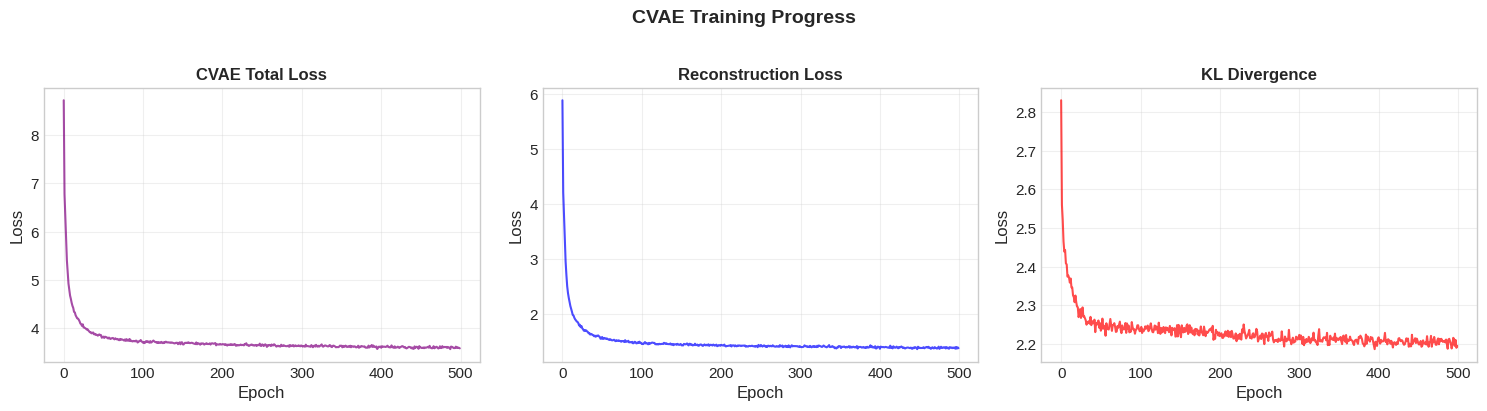


📈 Training Summary:
   Initial Loss: 8.7239
   Final Loss: 3.5802
   Improvement: 59.0%


In [23]:
# ============================================================
# CVAE Training Visualization
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Total Loss
axes[0].plot(cvae_history['loss'], color='purple', alpha=0.7)
axes[0].set_title('CVAE Total Loss', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.3)

# Reconstruction Loss
axes[1].plot(cvae_history['recon_loss'], color='blue', alpha=0.7)
axes[1].set_title('Reconstruction Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].grid(True, alpha=0.3)

# KL Divergence
axes[2].plot(cvae_history['kl_loss'], color='red', alpha=0.7)
axes[2].set_title('KL Divergence', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Loss')
axes[2].grid(True, alpha=0.3)

plt.suptitle('CVAE Training Progress', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n📈 Training Summary:")
print(f"   Initial Loss: {cvae_history['loss'][0]:.4f}")
print(f"   Final Loss: {cvae_history['loss'][-1]:.4f}")
print(f"   Improvement: {((cvae_history['loss'][0] - cvae_history['loss'][-1]) / cvae_history['loss'][0] * 100):.1f}%")

In [26]:
# ============================================================
# Generate Synthetic Data with CVAE
# ============================================================

print("=" * 60)
print("🎯 CVAE Synthetic Data Generation")
print("=" * 60)

# Calculate number of synthetic samples
n_cvae_original = len(cvae_train_df)
num_synthetic = int(n_cvae_original * CONFIG['synthetic_ratio'])

print(f"\n📊 Generation Plan:")
print(f"   • Original samples: {n_cvae_original:,}")
print(f"   • Synthetic ratio: {CONFIG['synthetic_ratio']}x")
print(f"   • Generating: {num_synthetic:,} synthetic samples\n")

# Generate conditions (sample from existing distribution)
condition_values = cvae_encoded_data[condition_col].values
sampled_conditions = np.random.choice(condition_values, size=num_synthetic)
sampled_conditions_scaled = (sampled_conditions - cvae_scaler.mean_[condition_idx]) / cvae_scaler.scale_[condition_idx]
C_sample = torch.FloatTensor(sampled_conditions_scaled.reshape(-1, 1)).to(device)

# Generate synthetic samples
cvae_model.eval()
cvae_gen_start = time.time()

with torch.no_grad():
    synthetic_features = cvae_model.sample(num_synthetic, C_sample, device)

cvae_gen_time = time.time() - cvae_gen_start

# Reconstruct full data (insert conditions back)
synthetic_features_np = synthetic_features.cpu().numpy()
synthetic_full = np.insert(synthetic_features_np, condition_idx, sampled_conditions_scaled, axis=1)

# Inverse transform: denormalize
synthetic_denorm = cvae_scaler.inverse_transform(synthetic_full)

# Decode back to original values
cvae_synthetic_df = pd.DataFrame(columns=CVAE_COLUMNS)
for i, col in enumerate(CVAE_COLUMNS):
    # Round to nearest integer and clip to valid range
    encoded_vals = np.round(synthetic_denorm[:, i]).astype(int)
    encoded_vals = np.clip(encoded_vals, 0, len(cvae_encoders[col].classes_) - 1)
    cvae_synthetic_df[col] = cvae_encoders[col].inverse_transform(encoded_vals)

print(cvae_synthetic_df.describe(include='all').T)

print(f"\n✅ Generated {len(cvae_synthetic_df)} CVAE synthetic samples in {cvae_gen_time:.2f}s")
print(f"\n📈 CVAE Synthetic Data Statistics:")

print(f"\n📊 CVAE Synthetic Data Sample:")
display(cvae_synthetic_df.head(10))

🎯 CVAE Synthetic Data Generation

📊 Generation Plan:
   • Original samples: 25,418
   • Synthetic ratio: 2.0x
   • Generating: 50,836 synthetic samples

                            count unique  \
malicious                   50836      1   
cyber_kill_chain_tactic     50836      6   
cyber_kill_chain_technique  50836      6   
_source.rule.mitre.id       50836     70   
_source.rule.mitre.tactic   50836     27   
_source.rule.level          50836      9   
_source.rule.groups         50836     21   
_source.decoder.name        50836     12   
_source.data.protocol       50836      7   
has_audit                   50836      2   
has_syscheck                50836      2   
has_sca                     50836      2   

                                                              top   freq  
malicious                                                       1  50836  
cyber_kill_chain_tactic                                        S3  36757  
cyber_kill_chain_technique                       

,malicious,cyber_kill_chain_tactic,cyber_kill_chain_technique,_source.rule.mitre.id,_source.rule.mitre.tactic,_source.rule.level,_source.rule.groups,_source.decoder.name,_source.data.protocol,has_audit,has_syscheck,has_sca
0,1,S3,S4,"[""T1055"",""T1190""]","[""TA0005"",""TA0004"",""TA0001""]",6,"[""web"",""accesslog"",""attack""]",web-accesslog,GET,False,False,False
1,1,S3,S3,"[""T1110.001"",""T1021.004"",""T1078""]","[""TA0005"",""TA0003"",""TA0004"",""TA0001"",""TA0008""]",3,"[""syslog"",""sshd"",""authentication_failed"",""inva...",sshd,MISSING,False,False,False
2,1,S3,S4,"[""T1055"",""T1083""]","[""TA0005"",""TA0004"",""TA0007"",""TA0001""]",6,"[""web"",""accesslog"",""attack""]",web-accesslog,GET,False,False,False
3,1,S3,S4,"[""T1059""]","[""TA0005"",""TA0004"",""TA0007""]",6,"[""web"",""accesslog"",""attack""]",web-accesslog,GET,False,False,False
4,1,S3,S4,"[""T1078"",""T1078.002"",""T1078.003""]","[""TA0005"",""TA0003"",""TA0004"",""TA0001""]",5,"[""web"",""accesslog"",""attack"",""sqlinjection"",""at...",syscheck_new_entry,HEAD,False,False,False
5,1,S3,S4,"[""T1068"",""T1203"",""T1211"",""T1212""]","[""TA0005"",""TA0003"",""TA0004"",""TA0001"",""TA0008""]",6,"[""web"",""accesslog"",""attack""]",web-accesslog,GET,False,False,False
6,1,S3,S4,"[""T1055""]","[""TA0005"",""TA0004"",""TA0007"",""TA0001""]",6,"[""web"",""accesslog"",""attack"",""sqlinjection"",""at...",useradd,GET,False,False,False
7,1,S3,S5,"[""T1055"",""T1083""]","[""TA0005"",""TA0004"",""TA0007"",""TA0001""]",4,"[""web"",""accesslog"",""attack""]",web-accesslog,GET,False,False,False
8,1,S3,S4,"[""T1055"",""T1083""]","[""TA0005"",""TA0004"",""TA0001""]",6,"[""web"",""accesslog"",""attack""]",web-accesslog,GET,False,False,False
9,1,S3,S4,"[""T1070"",""T1070.002"",""T1562"",""T1562.006""]","[""TA0005"",""TA0003"",""TA0004"",""TA0001""]",5,"[""pam"",""syslog"",""authentication_success""]",sshd,MISSING,True,True,True


In [27]:
# ============================================================================
# 📊 COMPREHENSIVE MODEL COMPARISON: CTGAN vs TVAE vs CVAE
# ============================================================================

print("=" * 70)
print("📊 COMPREHENSIVE MODEL COMPARISON: CTGAN vs TVAE vs CVAE")
print("=" * 70)

from scipy.stats import ks_2samp, chi2_contingency
from sklearn.metrics import mutual_info_score
import warnings
warnings.filterwarnings('ignore')

def evaluate_synthetic_quality(real_df, synth_df, discrete_cols, model_name):
    """Evaluate synthetic data quality with comprehensive metrics"""
    results = {
        'numeric': [],
        'categorical': [],
        'column_stats': {},
        'overall': {}
    }

    # Common columns
    common_cols = [c for c in real_df.columns if c in synth_df.columns]

    for col in common_cols:
        real_vals = real_df[col].dropna()
        synth_vals = synth_df[col].dropna()

        if len(real_vals) == 0 or len(synth_vals) == 0:
            continue

        if col in discrete_cols or real_vals.dtype == 'object':
            # Categorical metrics
            real_dist = real_vals.value_counts(normalize=True)
            synth_dist = synth_vals.value_counts(normalize=True)
            all_cats = set(real_dist.index) | set(synth_dist.index)

            # L1 distance (Total Variation Distance)
            l1 = sum(abs(real_dist.get(c, 0) - synth_dist.get(c, 0)) for c in all_cats)

            # Coverage
            coverage = len(set(real_dist.index) & set(synth_dist.index)) / len(real_dist) * 100

            # Jensen-Shannon Divergence (bounded [0, 1])
            eps = 1e-10
            p = np.array([real_dist.get(c, 0) + eps for c in all_cats])
            q = np.array([synth_dist.get(c, 0) + eps for c in all_cats])
            p = p / p.sum()
            q = q / q.sum()
            m = 0.5 * (p + q)
            js_div = 0.5 * (np.sum(p * np.log(p / m)) + np.sum(q * np.log(q / m)))

            results['categorical'].append({
                'column': col,
                'l1': l1,
                'coverage': coverage,
                'js_divergence': js_div,
                'unique_real': len(real_dist),
                'unique_synth': len(synth_dist)
            })
        else:
            # Numeric metrics
            try:
                real_numeric = pd.to_numeric(real_vals, errors='coerce').dropna()
                synth_numeric = pd.to_numeric(synth_vals, errors='coerce').dropna()
                if len(real_numeric) > 0 and len(synth_numeric) > 0:
                    ks_stat, ks_pval = ks_2samp(real_numeric, synth_numeric)

                    # Mean/std comparison
                    mean_diff = abs(real_numeric.mean() - synth_numeric.mean()) / (real_numeric.std() + 1e-10)
                    std_ratio = synth_numeric.std() / (real_numeric.std() + 1e-10)

                    results['numeric'].append({
                        'column': col,
                        'ks': ks_stat,
                        'ks_pval': ks_pval,
                        'mean_diff': mean_diff,
                        'std_ratio': std_ratio
                    })
            except:
                pass

    return results

# Evaluate all three models
print("\n🔍 Evaluating synthetic data quality...")

ctgan_results = evaluate_synthetic_quality(ctgan_data, synthetic_ctgan, ctgan_discrete_cols, 'CTGAN')
tvae_results = evaluate_synthetic_quality(tvae_data, synthetic_tvae, tvae_discrete_cols, 'TVAE')

# For CVAE, use same discrete cols as TVAE
cvae_discrete_cols = tvae_discrete_cols.copy()
cvae_results = evaluate_synthetic_quality(
    cvae_train_df,
    cvae_synthetic_df,
    cvae_discrete_cols,
    'CVAE'
)

# ========== COMPREHENSIVE SUMMARY ==========
def summarize_results(results, model_name):
    """Create comprehensive summary statistics"""
    summary = {
        'model': model_name,
        'num_cols_evaluated': len(results['numeric']) + len(results['categorical']),
    }

    if results['numeric']:
        summary['avg_ks'] = np.mean([r['ks'] for r in results['numeric']])
        summary['avg_mean_diff'] = np.mean([r['mean_diff'] for r in results['numeric']])
        summary['avg_std_ratio'] = np.mean([r['std_ratio'] for r in results['numeric']])
    else:
        summary['avg_ks'] = 0
        summary['avg_mean_diff'] = 0
        summary['avg_std_ratio'] = 1

    if results['categorical']:
        summary['avg_l1'] = np.mean([r['l1'] for r in results['categorical']])
        summary['avg_coverage'] = np.mean([r['coverage'] for r in results['categorical']])
        summary['avg_js_div'] = np.mean([r['js_divergence'] for r in results['categorical']])
    else:
        summary['avg_l1'] = 0
        summary['avg_coverage'] = 100
        summary['avg_js_div'] = 0

    # Composite quality score (lower is better)
    summary['quality_score'] = (
        summary['avg_ks'] * 0.25 +
        summary['avg_l1'] * 0.25 +
        summary['avg_js_div'] * 0.25 +
        (1 - summary['avg_coverage']/100) * 0.25
    )

    return summary

ctgan_summary = summarize_results(ctgan_results, 'CTGAN')
tvae_summary = summarize_results(tvae_results, 'TVAE')
cvae_summary = summarize_results(cvae_results, 'CVAE')

# Print detailed comparison
print("\n" + "=" * 70)
print("📊 DETAILED QUALITY COMPARISON")
print("=" * 70)

comparison_df = pd.DataFrame([ctgan_summary, tvae_summary, cvae_summary])
comparison_df = comparison_df.set_index('model')

print(f"""
┌─────────────────────────────────────────────────────────────────────────────┐
│                        SYNTHETIC DATA QUALITY METRICS                        │
├────────────────────┬──────────────┬──────────────┬──────────────────────────┤
│      Metric        │    CTGAN     │     TVAE     │         CVAE             │
├────────────────────┼──────────────┼──────────────┼──────────────────────────┤
│ Avg KS Statistic   │   {ctgan_summary['avg_ks']:>8.4f}   │   {tvae_summary['avg_ks']:>8.4f}   │        {cvae_summary['avg_ks']:>8.4f}           │
│ Avg L1 Distance    │   {ctgan_summary['avg_l1']:>8.4f}   │   {tvae_summary['avg_l1']:>8.4f}   │        {cvae_summary['avg_l1']:>8.4f}           │
│ Avg JS Divergence  │   {ctgan_summary['avg_js_div']:>8.4f}   │   {tvae_summary['avg_js_div']:>8.4f}   │        {cvae_summary['avg_js_div']:>8.4f}           │
│ Avg Coverage (%)   │   {ctgan_summary['avg_coverage']:>8.1f}   │   {tvae_summary['avg_coverage']:>8.1f}   │        {cvae_summary['avg_coverage']:>8.1f}           │
├────────────────────┼──────────────┼──────────────┼──────────────────────────┤
│ Quality Score ↓    │   {ctgan_summary['quality_score']:>8.4f}   │   {tvae_summary['quality_score']:>8.4f}   │        {cvae_summary['quality_score']:>8.4f}           │
└────────────────────┴──────────────┴──────────────┴──────────────────────────┘

📝 Interpretation Guide:
   • KS Statistic: Lower is better (<0.2 good, <0.3 acceptable)
   • L1 Distance: Lower is better (<0.2 good, <0.4 acceptable)
   • JS Divergence: Lower is better (0 = identical distributions)
   • Coverage: Higher is better (% of original categories captured)
   • Quality Score: Composite metric, lower is better
""")

# Determine best model
all_scores = [
    ('CTGAN', ctgan_summary['quality_score'], synthetic_ctgan),
    ('TVAE', tvae_summary['quality_score'], synthetic_tvae),
    ('CVAE', cvae_summary['quality_score'], cvae_synthetic_df)
]
all_scores.sort(key=lambda x: x[1])

best_model = all_scores[0][0]
best_synthetic = all_scores[0][2]
best_score = all_scores[0][1]

print(f"\n{'='*70}")
print(f"🏆 MODEL RANKING (Best to Worst)")
print(f"{'='*70}")
for rank, (model, score, _) in enumerate(all_scores, 1):
    medal = ['🥇', '🥈', '🥉'][rank-1]
    print(f"   {medal} #{rank}: {model} (Quality Score: {score:.4f})")

print(f"\n{'='*70}")
print(f"🎯 RECOMMENDED MODEL: {best_model}")
print(f"{'='*70}")

# Store results for later use
model_comparison_results = {
    'ctgan': ctgan_summary,
    'tvae': tvae_summary,
    'cvae': cvae_summary,
    'best_model': best_model,
    'ranking': [m[0] for m in all_scores]
}

📊 COMPREHENSIVE MODEL COMPARISON: CTGAN vs TVAE vs CVAE

🔍 Evaluating synthetic data quality...

📊 DETAILED QUALITY COMPARISON

┌─────────────────────────────────────────────────────────────────────────────┐
│                        SYNTHETIC DATA QUALITY METRICS                        │
├────────────────────┬──────────────┬──────────────┬──────────────────────────┤
│      Metric        │    CTGAN     │     TVAE     │         CVAE             │
├────────────────────┼──────────────┼──────────────┼──────────────────────────┤
│ Avg KS Statistic   │     0.0000   │     0.0000   │          0.0000           │
│ Avg L1 Distance    │     0.6487   │     0.2211   │          0.3610           │
│ Avg JS Divergence  │     0.0803   │     0.0464   │          0.0717           │
│ Avg Coverage (%)   │      100.0   │       97.9   │            91.9           │
├────────────────────┼──────────────┼──────────────┼──────────────────────────┤
│ Quality Score ↓    │     0.1822   │     0.0720   │          0.128

---
## 📈 Part 9: Comprehensive 3-Model Visualization

This section provides detailed visualizations comparing all three generative models:
- **Distribution Comparisons**: How well each model captures the original distributions
- **Quality Metrics**: Side-by-side comparison of all evaluation metrics
- **Training Dynamics**: Training curves and convergence analysis
- **Category Coverage**: How well each model captures categorical diversity

📈 COMPREHENSIVE 3-MODEL VISUALIZATION


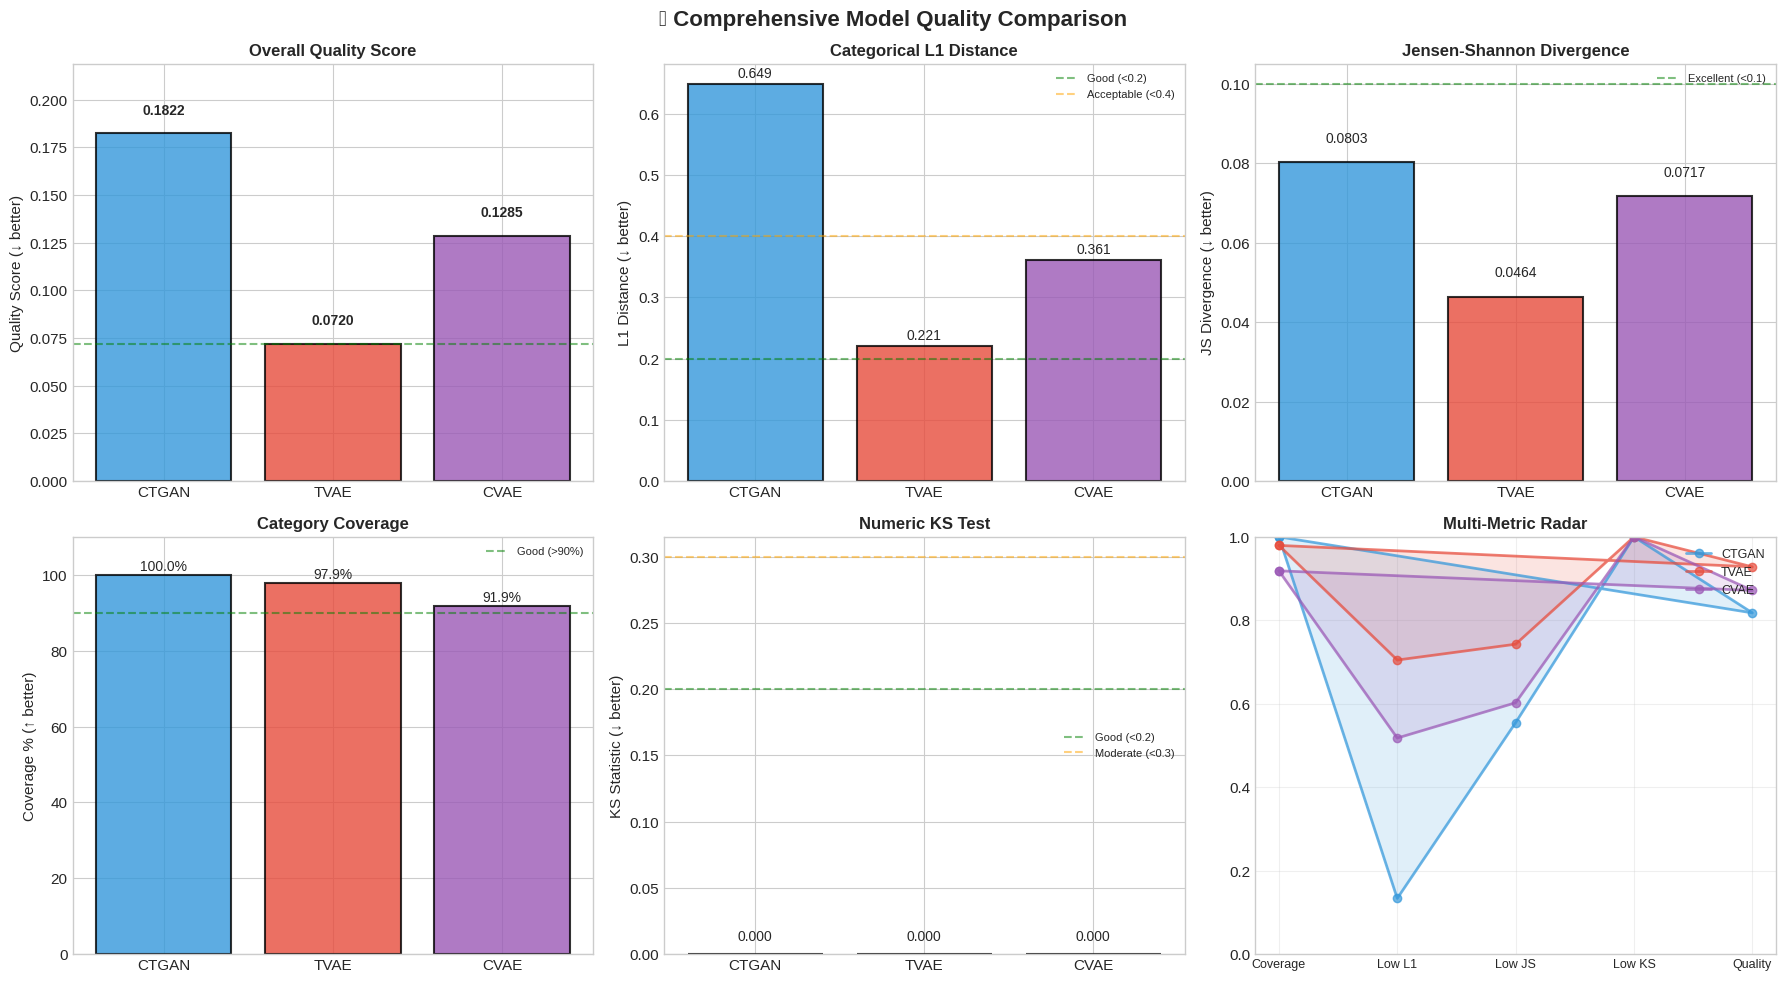

✅ Metrics comparison saved


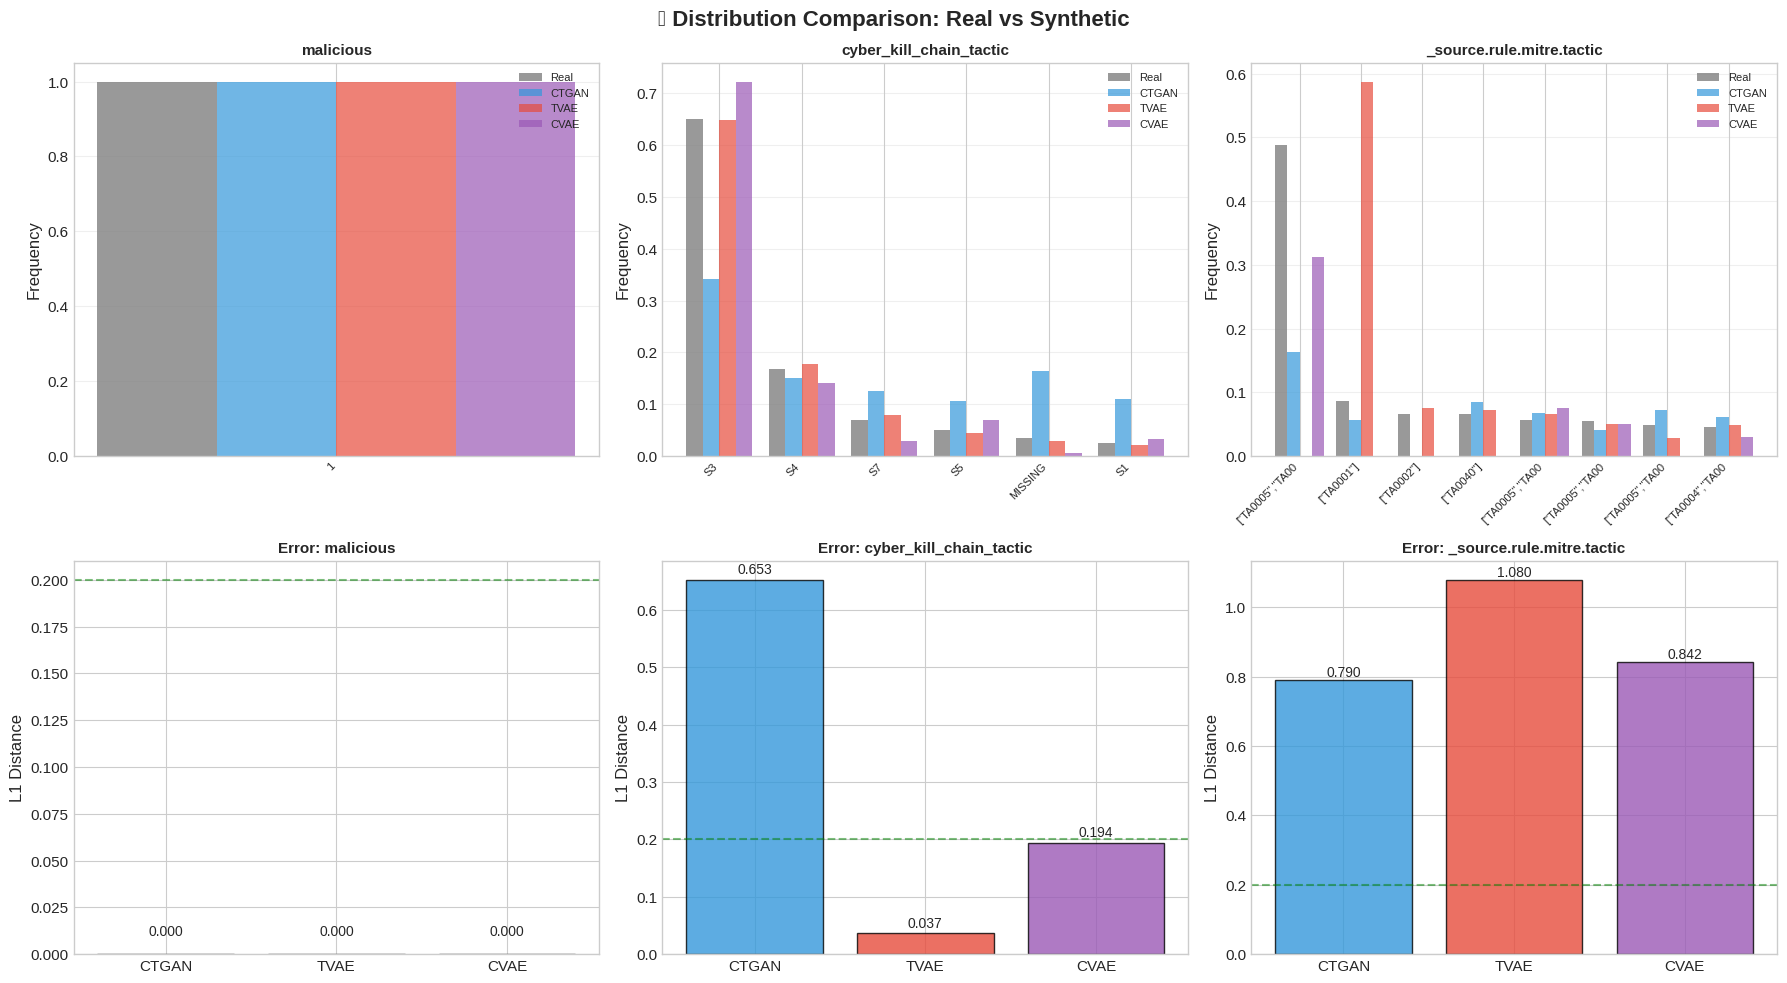

✅ Distribution comparison saved


In [28]:
# ============================================================================
# 📈 COMPREHENSIVE 3-MODEL VISUALIZATION
# ============================================================================

print("=" * 70)
print("📈 COMPREHENSIVE 3-MODEL VISUALIZATION")
print("=" * 70)

# Color scheme for consistency
COLORS = {
    'CTGAN': '#3498db',  # Blue
    'TVAE': '#e74c3c',   # Red
    'CVAE': '#9b59b6'    # Purple
}

# ============== Figure 1: Quality Metrics Comparison ==============
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('📊 Comprehensive Model Quality Comparison', fontsize=16, fontweight='bold')

# 1.1 - Quality Score (Main Metric)
ax = axes[0, 0]
models = ['CTGAN', 'TVAE', 'CVAE']
scores = [ctgan_summary['quality_score'], tvae_summary['quality_score'], cvae_summary['quality_score']]
colors = [COLORS[m] for m in models]
bars = ax.bar(models, scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=min(scores), color='green', linestyle='--', alpha=0.5, label='Best')
ax.set_ylabel('Quality Score (↓ better)', fontsize=11)
ax.set_title('Overall Quality Score', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(scores) * 1.2)
for bar, score in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{score:.4f}', ha='center', fontsize=10, fontweight='bold')

# 1.2 - L1 Distance (Categorical)
ax = axes[0, 1]
l1_scores = [ctgan_summary['avg_l1'], tvae_summary['avg_l1'], cvae_summary['avg_l1']]
bars = ax.bar(models, l1_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=0.2, color='green', linestyle='--', alpha=0.5, label='Good (<0.2)')
ax.axhline(y=0.4, color='orange', linestyle='--', alpha=0.5, label='Acceptable (<0.4)')
ax.set_ylabel('L1 Distance (↓ better)', fontsize=11)
ax.set_title('Categorical L1 Distance', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
for bar, score in zip(bars, l1_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{score:.3f}', ha='center', fontsize=10)

# 1.3 - JS Divergence
ax = axes[0, 2]
js_scores = [ctgan_summary['avg_js_div'], tvae_summary['avg_js_div'], cvae_summary['avg_js_div']]
bars = ax.bar(models, js_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=0.1, color='green', linestyle='--', alpha=0.5, label='Excellent (<0.1)')
ax.set_ylabel('JS Divergence (↓ better)', fontsize=11)
ax.set_title('Jensen-Shannon Divergence', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
for bar, score in zip(bars, js_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{score:.4f}', ha='center', fontsize=10)

# 1.4 - Coverage
ax = axes[1, 0]
coverage_scores = [ctgan_summary['avg_coverage'], tvae_summary['avg_coverage'], cvae_summary['avg_coverage']]
bars = ax.bar(models, coverage_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=90, color='green', linestyle='--', alpha=0.5, label='Good (>90%)')
ax.set_ylabel('Coverage % (↑ better)', fontsize=11)
ax.set_title('Category Coverage', fontsize=12, fontweight='bold')
ax.set_ylim(0, 110)
ax.legend(fontsize=8)
for bar, score in zip(bars, coverage_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{score:.1f}%', ha='center', fontsize=10)

# 1.5 - KS Statistic (Numeric)
ax = axes[1, 1]
ks_scores = [ctgan_summary['avg_ks'], tvae_summary['avg_ks'], cvae_summary['avg_ks']]
bars = ax.bar(models, ks_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=0.2, color='green', linestyle='--', alpha=0.5, label='Good (<0.2)')
ax.axhline(y=0.3, color='orange', linestyle='--', alpha=0.5, label='Moderate (<0.3)')
ax.set_ylabel('KS Statistic (↓ better)', fontsize=11)
ax.set_title('Numeric KS Test', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
for bar, score in zip(bars, ks_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{score:.3f}', ha='center', fontsize=10)

# 1.6 - Radar Chart Summary
ax = axes[1, 2]
# Normalize metrics for radar (all 0-1, higher = better)
max_l1 = max(l1_scores) + 0.1
max_js = max(js_scores) + 0.1
max_ks = max(ks_scores) + 0.1

radar_metrics = ['Coverage', 'Low L1', 'Low JS', 'Low KS', 'Quality']
angles = np.linspace(0, 2*np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]

for model, color in COLORS.items():
    if model == 'CTGAN':
        s = ctgan_summary
    elif model == 'TVAE':
        s = tvae_summary
    else:
        s = cvae_summary

    values = [
        s['avg_coverage']/100,
        1 - s['avg_l1']/max_l1,
        1 - s['avg_js_div']/max_js,
        1 - s['avg_ks']/max_ks,
        1 - s['quality_score']
    ]
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=model, color=color, alpha=0.7)
    ax.fill(angles, values, alpha=0.15, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metrics, fontsize=9)
ax.set_ylim(0, 1)
ax.set_title('Multi-Metric Radar', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CONFIG['output_dir']) / 'model_comparison_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Metrics comparison saved")

# ============== Figure 2: Distribution Comparison for Key Columns ==============
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('📊 Distribution Comparison: Real vs Synthetic', fontsize=16, fontweight='bold')

# Select key columns to compare
key_cols_to_plot = ['malicious', 'cyber_kill_chain_tactic', '_source.rule.mitre.tactic']
key_cols_to_plot = [c for c in key_cols_to_plot if c in CVAE_COLUMNS][:3]

for idx, col in enumerate(key_cols_to_plot):
    # Top row: Distribution comparison
    ax = axes[0, idx]

    # Get distributions
    real_dist = cvae_train_df[col].value_counts(normalize=True).head(10)
    ctgan_dist = synthetic_ctgan[col].value_counts(normalize=True).head(10) if col in synthetic_ctgan.columns else pd.Series()
    tvae_dist = synthetic_tvae[col].value_counts(normalize=True).head(10) if col in synthetic_tvae.columns else pd.Series()
    cvae_dist = cvae_synthetic_df[col].value_counts(normalize=True).head(10) if col in cvae_synthetic_df.columns else pd.Series()

    all_cats = list(real_dist.index)[:8]
    x = np.arange(len(all_cats))
    width = 0.2

    ax.bar(x - 1.5*width, [real_dist.get(c, 0) for c in all_cats], width, label='Real', color='gray', alpha=0.8)
    ax.bar(x - 0.5*width, [ctgan_dist.get(c, 0) for c in all_cats], width, label='CTGAN', color=COLORS['CTGAN'], alpha=0.7)
    ax.bar(x + 0.5*width, [tvae_dist.get(c, 0) for c in all_cats], width, label='TVAE', color=COLORS['TVAE'], alpha=0.7)
    ax.bar(x + 1.5*width, [cvae_dist.get(c, 0) for c in all_cats], width, label='CVAE', color=COLORS['CVAE'], alpha=0.7)

    ax.set_xticks(x)
    ax.set_xticklabels([str(c)[:15] for c in all_cats], rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('Frequency')
    ax.set_title(f'{col}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')

# Bottom row: Error analysis
for idx, col in enumerate(key_cols_to_plot):
    ax = axes[1, idx]

    real_dist = cvae_train_df[col].value_counts(normalize=True)

    errors = {}
    for model, synth_df, color in [('CTGAN', synthetic_ctgan, COLORS['CTGAN']),
                                     ('TVAE', synthetic_tvae, COLORS['TVAE']),
                                     ('CVAE', cvae_synthetic_df, COLORS['CVAE'])]:
        if col in synth_df.columns:
            synth_dist = synth_df[col].value_counts(normalize=True)
            all_cats = set(real_dist.index) | set(synth_dist.index)
            l1 = sum(abs(real_dist.get(c, 0) - synth_dist.get(c, 0)) for c in all_cats)
            errors[model] = l1

    bars = ax.bar(list(errors.keys()), list(errors.values()),
                  color=[COLORS[m] for m in errors.keys()], alpha=0.8, edgecolor='black')
    ax.axhline(y=0.2, color='green', linestyle='--', alpha=0.5)
    ax.set_ylabel('L1 Distance')
    ax.set_title(f'Error: {col}', fontsize=11, fontweight='bold')
    for bar, (model, err) in zip(bars, errors.items()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{err:.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig(Path(CONFIG['output_dir']) / 'distribution_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Distribution comparison saved")

⏱️ TRAINING TIME & EFFICIENCY COMPARISON


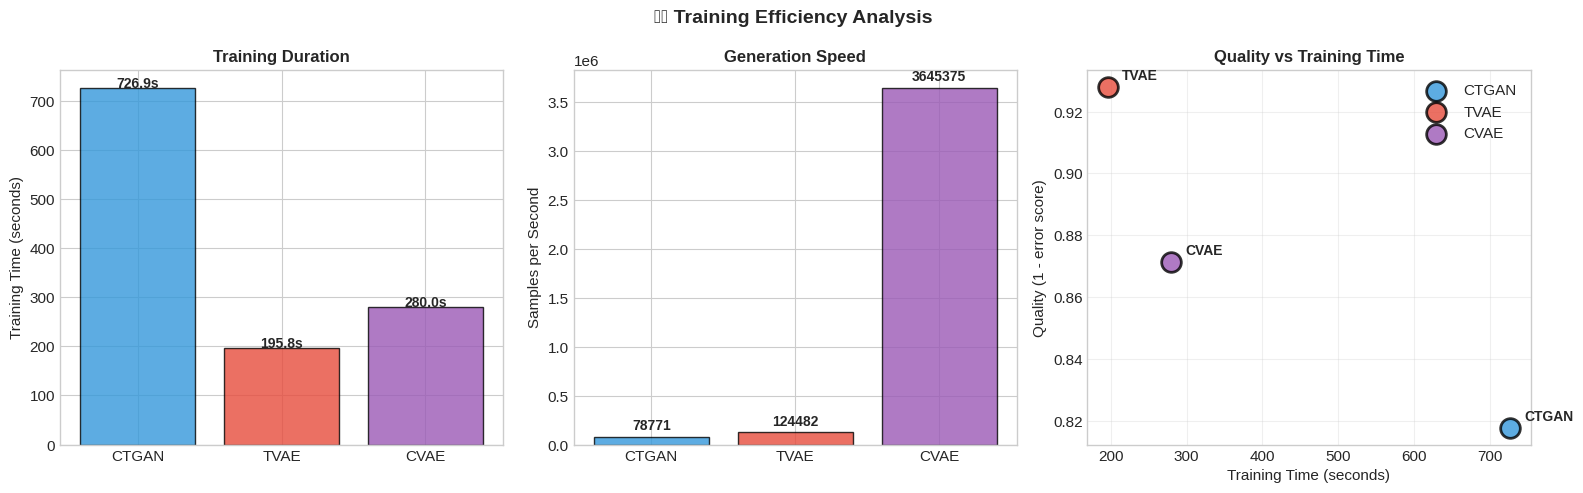


┌───────────────────────────────────────────────────────────────────────────────┐
│                           EFFICIENCY SUMMARY                                   │
├─────────────────┬───────────────┬───────────────┬────────────────────────────┤
│     Metric      │     CTGAN     │      TVAE     │           CVAE              │
├─────────────────┼───────────────┼───────────────┼────────────────────────────┤
│ Training Time   │      726.9s   │      195.8s   │           280.0s            │
│ Gen Speed       │      78771/s   │     124482/s   │         3645375/s            │
│ Quality Score   │     0.1822    │     0.0720    │          0.1285             │
└─────────────────┴───────────────┴───────────────┴────────────────────────────┘



In [31]:
# ============================================================================
# ⏱️ TRAINING TIME & EFFICIENCY COMPARISON
# ============================================================================

print("=" * 70)
print("⏱️ TRAINING TIME & EFFICIENCY COMPARISON")
print("=" * 70)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('⏱️ Training Efficiency Analysis', fontsize=14, fontweight='bold')

# 1. Training Time Comparison
ax = axes[0]
training_times = {
    'CTGAN': train_duration * 60,  # Convert minutes to seconds
    'TVAE': tvae_train_duration * 60,  # Convert minutes to seconds
    'CVAE': cvae_training_time  # Already in seconds
}
bars = ax.bar(training_times.keys(), training_times.values(),
              color=[COLORS[m] for m in training_times.keys()], alpha=0.8, edgecolor='black')
ax.set_ylabel('Training Time (seconds)', fontsize=11)
ax.set_title('Training Duration', fontsize=12, fontweight='bold')
for bar, (model, time_val) in zip(bars, training_times.items()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{time_val:.1f}s', ha='center', fontsize=10, fontweight='bold')

# 2. Samples Generated per Second
ax = axes[1]
gen_efficiency = {
    'CTGAN': len(synthetic_ctgan) / max(gen_duration, 0.01),
    'TVAE': len(synthetic_tvae) / max(tvae_gen_duration, 0.01),
    'CVAE': len(cvae_synthetic_df) / max(cvae_gen_time, 0.01)
}
bars = ax.bar(gen_efficiency.keys(), gen_efficiency.values(),
              color=[COLORS[m] for m in gen_efficiency.keys()], alpha=0.8, edgecolor='black')
ax.set_ylabel('Samples per Second', fontsize=11)
ax.set_title('Generation Speed', fontsize=12, fontweight='bold')
for bar, (model, speed) in zip(bars, gen_efficiency.items()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(gen_efficiency.values())*0.02,
            f'{speed:.0f}', ha='center', fontsize=10, fontweight='bold')

# 3. Quality vs Training Time Trade-off
ax = axes[2]
for model in ['CTGAN', 'TVAE', 'CVAE']:
    if model == 'CTGAN':
        quality = ctgan_summary['quality_score']
        train_time = train_duration * 60  # Convert to seconds
    elif model == 'TVAE':
        quality = tvae_summary['quality_score']
        train_time = tvae_train_duration * 60  # Convert to seconds
    else:
        quality = cvae_summary['quality_score']
        train_time = cvae_training_time  # Already in seconds

    ax.scatter(train_time, 1 - quality, s=200, c=COLORS[model], label=model,
               edgecolors='black', linewidths=2, alpha=0.8)
    ax.annotate(model, (train_time, 1 - quality), textcoords="offset points",
                xytext=(10, 5), fontsize=10, fontweight='bold')

ax.set_xlabel('Training Time (seconds)', fontsize=11)
ax.set_ylabel('Quality (1 - error score)', fontsize=11)
ax.set_title('Quality vs Training Time', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(Path(CONFIG['output_dir']) / 'training_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

# Print summary table
print(f"""
┌───────────────────────────────────────────────────────────────────────────────┐
│                           EFFICIENCY SUMMARY                                   │
├─────────────────┬───────────────┬───────────────┬────────────────────────────┤
│     Metric      │     CTGAN     │      TVAE     │           CVAE              │
├─────────────────┼───────────────┼───────────────┼────────────────────────────┤
│ Training Time   │   {training_times['CTGAN']:>8.1f}s   │   {training_times['TVAE']:>8.1f}s   │        {training_times['CVAE']:>8.1f}s            │
│ Gen Speed       │   {gen_efficiency['CTGAN']:>8.0f}/s   │   {gen_efficiency['TVAE']:>8.0f}/s   │        {gen_efficiency['CVAE']:>8.0f}/s            │
│ Quality Score   │   {ctgan_summary['quality_score']:>8.4f}    │   {tvae_summary['quality_score']:>8.4f}    │        {cvae_summary['quality_score']:>8.4f}             │
└─────────────────┴───────────────┴───────────────┴────────────────────────────┘
""")

---
## 💾 Part 10: Save Results

In [36]:
# ============================================================================
# 💾 SAVE ALL OUTPUTS (CTGAN, TVAE, CVAE)
# ============================================================================

print("=" * 70)
print("💾 SAVING ALL OUTPUTS")
print("=" * 70)

output_dir = Path(CONFIG['output_dir'])

# 1. Save CTGAN synthetic data
ctgan_path = output_dir / 'synthetic_ctgan.xlsx'
synthetic_ctgan.to_excel(ctgan_path, index=False)
print(f"✅ CTGAN synthetic data: {ctgan_path}")
print(f"   • Shape: {synthetic_ctgan.shape}")

# 2. Save TVAE synthetic data
tvae_path = output_dir / 'synthetic_tvae.xlsx'
synthetic_tvae.to_excel(tvae_path, index=False)
print(f"✅ TVAE synthetic data: {tvae_path}")
print(f"   • Shape: {synthetic_tvae.shape}")

# 3. Save CVAE synthetic data
cvae_path = output_dir / 'synthetic_cvae.xlsx'
cvae_synthetic_df.to_excel(cvae_path, index=False)
print(f"✅ CVAE synthetic data: {cvae_path}")
print(f"   • Shape: {cvae_synthetic_df.shape}")

# 4. Save best model synthetic data
best_path = output_dir / f'synthetic_best_{best_model.lower()}.xlsx'
best_synthetic.to_excel(best_path, index=False)
print(f"✅ Best model ({best_model}) data: {best_path}")

# 5. Save combined datasets (real + synthetic)
combined_ctgan = pd.concat([
    ctgan_data.assign(data_source='real'),
    synthetic_ctgan.assign(data_source='synthetic_ctgan')
], ignore_index=True)
combined_ctgan_path = output_dir / 'combined_ctgan.xlsx'
combined_ctgan.to_excel(combined_ctgan_path, index=False)
print(f"✅ Combined CTGAN data: {combined_ctgan_path}")
print(f"   • Shape: {combined_ctgan.shape}")

combined_tvae = pd.concat([
    tvae_data.assign(data_source='real'),
    synthetic_tvae.assign(data_source='synthetic_tvae')
], ignore_index=True)
combined_tvae_path = output_dir / 'combined_tvae.xlsx'
combined_tvae.to_excel(combined_tvae_path, index=False)
print(f"✅ Combined TVAE data: {combined_tvae_path}")
print(f"   • Shape: {combined_tvae.shape}")

combined_cvae = pd.concat([
    cvae_train_df.assign(data_source='real'),
    cvae_synthetic_df.assign(data_source='synthetic_cvae')
], ignore_index=True)
combined_cvae_path = output_dir / 'combined_cvae.xlsx'
combined_cvae.to_excel(combined_cvae_path, index=False)
print(f"✅ Combined CVAE data: {combined_cvae_path}")
print(f"   • Shape: {combined_cvae.shape}")

# 6. Save comprehensive quality report
quality_report = {
    'timestamp': datetime.now().isoformat(),
    'config': {
        'synthetic_ratio': CONFIG['synthetic_ratio'],
        'ctgan_epochs': CONFIG['ctgan_epochs'],
        'tvae_epochs': CONFIG['tvae_epochs'],
        'cvae_epochs': CONFIG['cvae_epochs'],
    },
    'ctgan': {
        'columns': CTGAN_COLUMNS,
        'original_samples': len(ctgan_data),
        'synthetic_samples': len(synthetic_ctgan),
        'training_time_seconds': train_duration * 60,  # Convert minutes to seconds
        'metrics': {
            'avg_ks': ctgan_summary['avg_ks'],
            'avg_l1': ctgan_summary['avg_l1'],
            'avg_coverage': ctgan_summary['avg_coverage'],
            'avg_js_divergence': ctgan_summary['avg_js_div'],
            'quality_score': ctgan_summary['quality_score'],
        }
    },
    'tvae': {
        'columns': TVAE_COLUMNS,
        'original_samples': len(tvae_data),
        'synthetic_samples': len(synthetic_tvae),
        'training_time_seconds': tvae_train_duration * 60,  # Convert minutes to seconds
        'metrics': {
            'avg_ks': tvae_summary['avg_ks'],
            'avg_l1': tvae_summary['avg_l1'],
            'avg_coverage': tvae_summary['avg_coverage'],
            'avg_js_divergence': tvae_summary['avg_js_div'],
            'quality_score': tvae_summary['quality_score'],
        }
    },
    'cvae': {
        'columns': CVAE_COLUMNS,
        'original_samples': len(cvae_train_df),
        'synthetic_samples': len(cvae_synthetic_df),
        'training_time_seconds': cvae_training_time,
        'architecture': {
            'latent_dim': CONFIG['cvae_latent_dim'],
            'hidden_dims': CONFIG['cvae_hidden_dims'],
            'beta': CONFIG['cvae_beta'],
        },
        'metrics': {
            'avg_ks': cvae_summary['avg_ks'],
            'avg_l1': cvae_summary['avg_l1'],
            'avg_coverage': cvae_summary['avg_coverage'],
            'avg_js_divergence': cvae_summary['avg_js_div'],
            'quality_score': cvae_summary['quality_score'],
        }
    },
    'comparison': {
        'ranking': model_comparison_results['ranking'],
        'best_model': best_model,
    }
}

report_path = output_dir / 'quality_report.json'
with open(report_path, 'w') as f:
    json.dump(quality_report, f, indent=2)
print(f"✅ Quality report: {report_path}")

# 7. Save models
ctgan.save(str(output_dir / 'ctgan_model.pkl'))
tvae.save(str(output_dir / 'tvae_model.pkl'))

# Save CVAE model (PyTorch)
cvae_model_path = output_dir / 'cvae_model.pth'
torch.save({
    'model_state_dict': cvae_model.state_dict(),
    'input_dim': input_dim,
    'condition_dim': condition_dim,
    'latent_dim': CONFIG['cvae_latent_dim'],
    'hidden_dims': CONFIG['cvae_hidden_dims'],
    'encoders': {col: list(enc.classes_) for col, enc in cvae_encoders.items()},
    'scaler_mean': cvae_scaler.mean_.tolist(),
    'scaler_scale': cvae_scaler.scale_.tolist(),
    'columns': CVAE_COLUMNS,
}, cvae_model_path)
print(f"✅ CVAE model: {cvae_model_path}")

print(f"✅ CTGAN model: {output_dir / 'ctgan_model.pkl'}")
print(f"✅ TVAE model: {output_dir / 'tvae_model.pkl'}")

print("\n" + "=" * 70)
print(f"📁 ALL OUTPUTS SAVED TO: {output_dir}/")
print("=" * 70)

💾 SAVING ALL OUTPUTS
✅ CTGAN synthetic data: ctgan_output/synthetic_ctgan.xlsx
   • Shape: (50836, 9)
✅ TVAE synthetic data: ctgan_output/synthetic_tvae.xlsx
   • Shape: (50836, 12)
✅ CVAE synthetic data: ctgan_output/synthetic_cvae.xlsx
   • Shape: (50836, 12)
✅ Best model (TVAE) data: ctgan_output/synthetic_best_tvae.xlsx
✅ Combined CTGAN data: ctgan_output/combined_ctgan.xlsx
   • Shape: (76254, 10)
✅ Combined TVAE data: ctgan_output/combined_tvae.xlsx
   • Shape: (76254, 13)
✅ Combined CVAE data: ctgan_output/combined_cvae.xlsx
   • Shape: (76254, 13)
✅ Quality report: ctgan_output/quality_report.json
✅ CVAE model: ctgan_output/cvae_model.pth
✅ CTGAN model: ctgan_output/ctgan_model.pkl
✅ TVAE model: ctgan_output/tvae_model.pkl

📁 ALL OUTPUTS SAVED TO: ctgan_output/


---
## 🏁 Final Summary

In [37]:
# ============================================================================
# 🏁 FINAL SUMMARY - ALL THREE MODELS
# ============================================================================

print("=" * 70)
print("🏁 CTGAN, TVAE & CVAE PIPELINE COMPLETE")
print("=" * 70)

print(f"""
╔══════════════════════════════════════════════════════════════════════════════╗
║                          📊 DATA SUMMARY                                      ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Model     │ Original Rows │ Synthetic │ Columns │ Training Time             ║
╠════════════╪═══════════════╪═══════════╪═════════╪═══════════════════════════╣
║  CTGAN     │    {len(ctgan_data):>8,}    │  {len(synthetic_ctgan):>7,}  │   {len(CTGAN_COLUMNS):>3}   │  {train_duration*60:>6.1f}s              ║
║  TVAE      │    {len(tvae_data):>8,}    │  {len(synthetic_tvae):>7,}  │   {len(TVAE_COLUMNS):>3}   │  {tvae_train_duration*60:>6.1f}s              ║
║  CVAE      │    {len(cvae_train_df):>8,}    │  {len(cvae_synthetic_df):>7,}  │   {len(CVAE_COLUMNS):>3}   │  {cvae_training_time:>6.1f}s              ║
╚══════════════════════════════════════════════════════════════════════════════╝

╔══════════════════════════════════════════════════════════════════════════════╗
║                          📈 QUALITY METRICS                                   ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Model  │ KS Stat ↓ │ L1 Dist ↓ │ JS Div ↓ │ Coverage ↑ │ Quality ↓         ║
╠═════════╪═══════════╪═══════════╪══════════╪════════════╪═══════════════════╣
║  CTGAN  │  {ctgan_summary['avg_ks']:>7.4f}  │  {ctgan_summary['avg_l1']:>7.4f}  │ {ctgan_summary['avg_js_div']:>7.4f} │   {ctgan_summary['avg_coverage']:>5.1f}%   │   {ctgan_summary['quality_score']:>7.4f}        ║
║  TVAE   │  {tvae_summary['avg_ks']:>7.4f}  │  {tvae_summary['avg_l1']:>7.4f}  │ {tvae_summary['avg_js_div']:>7.4f} │   {tvae_summary['avg_coverage']:>5.1f}%   │   {tvae_summary['quality_score']:>7.4f}        ║
║  CVAE   │  {cvae_summary['avg_ks']:>7.4f}  │  {cvae_summary['avg_l1']:>7.4f}  │ {cvae_summary['avg_js_div']:>7.4f} │   {cvae_summary['avg_coverage']:>5.1f}%   │   {cvae_summary['quality_score']:>7.4f}        ║
╚══════════════════════════════════════════════════════════════════════════════╝

╔══════════════════════════════════════════════════════════════════════════════╗
║                          🏆 MODEL RANKING                                     ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  🥇 1st Place: {model_comparison_results['ranking'][0]:<10} (Quality Score: {all_scores[0][1]:.4f})                   ║
║  🥈 2nd Place: {model_comparison_results['ranking'][1]:<10} (Quality Score: {all_scores[1][1]:.4f})                   ║
║  🥉 3rd Place: {model_comparison_results['ranking'][2]:<10} (Quality Score: {all_scores[2][1]:.4f})                   ║
╚══════════════════════════════════════════════════════════════════════════════╝

📁 OUTPUT FILES GENERATED:
   ├── synthetic_ctgan.xlsx       ({len(synthetic_ctgan):,} samples)
   ├── synthetic_tvae.xlsx        ({len(synthetic_tvae):,} samples)
   ├── synthetic_cvae.xlsx        ({len(cvae_synthetic_df):,} samples)
   ├── synthetic_best_{best_model.lower()}.xlsx
   ├── combined_ctgan.xlsx
   ├── combined_tvae.xlsx
   ├── combined_cvae.xlsx
   ├── quality_report.json
   ├── ctgan_model.pkl
   ├── tvae_model.pkl
   ├── cvae_model.pth
   ├── model_comparison_metrics.png
   ├── distribution_comparison.png
   └── training_efficiency.png

📝 INTERPRETATION:
   • Lower KS Statistic → Better numeric distribution matching
   • Lower L1 Distance → Better categorical distribution matching
   • Lower JS Divergence → More similar probability distributions
   • Higher Coverage → More original categories captured
   • Lower Quality Score → Overall better synthetic data quality

🎯 RECOMMENDED MODEL: {best_model}
   Use this model's synthetic data for downstream ML tasks.
""")

print("=" * 70)
print("🎉 Pipeline completed successfully!")
print("=" * 70)

🏁 CTGAN, TVAE & CVAE PIPELINE COMPLETE

╔══════════════════════════════════════════════════════════════════════════════╗
║                          📊 DATA SUMMARY                                      ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Model     │ Original Rows │ Synthetic │ Columns │ Training Time             ║
╠════════════╪═══════════════╪═══════════╪═════════╪═══════════════════════════╣
║  CTGAN     │      25,418    │   50,836  │     9   │   726.9s              ║
║  TVAE      │      25,418    │   50,836  │    12   │   195.8s              ║
║  CVAE      │      25,418    │   50,836  │    12   │   280.0s              ║
╚══════════════════════════════════════════════════════════════════════════════╝

╔══════════════════════════════════════════════════════════════════════════════╗
║                          📈 QUALITY METRICS                                   ║
╠════════════════════════════════════════════════════════════════════════════